# Retail Demand Forecasting & Commercial Planning Dashboard

## Executive Summary

This project analyzes historical retail sales data to build a commercial demand forecasting model that supports inventory planning, sales forecasting, and executive decision-making using Python, SQL, and Power BI.

---

## Business Problem

Retail companies need accurate sales forecasts to optimize inventory allocation, promotional campaigns, and commercial planning across multiple stores and product categories.

---

## Project Objectives

- Analyze historical sales behavior.
- Identify seasonality and demand patterns.
- Engineer forecasting features.
- Build demand forecasting models.
- Deliver executive insights through Power BI.

In [2]:
# ============================================
# Commercial Excellence Academy | Project 3
# Retail Demand Forecasting Dashboard
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
# Load datasets

train = pd.read_csv("../1. Data/Raw/train.csv")
stores = pd.read_csv("../1. Data/Raw/stores.csv")
transactions = pd.read_csv("../1. Data/Raw/transactions.csv")
oil = pd.read_csv("../1. Data/Raw/oil.csv")
holidays = pd.read_csv("../1. Data/Raw/holidays_events.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [4]:
# ============================================
# Dataset dimensions
# ============================================

datasets = {
    "Train": train,
    "Stores": stores,
    "Transactions": transactions,
    "Oil": oil,
    "Holidays": holidays
}

summary = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()]
})

summary

,Dataset,Rows,Columns
0,Train,3000888,6
1,Stores,54,5
2,Transactions,83488,3
3,Oil,1218,2
4,Holidays,350,6


In [5]:
# First look at train.csv

train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [7]:
train.describe(include="all")

,id,date,store_nbr,family,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3000888,3.000888e+06,3.000888e+06
unique,NaN,1684,NaN,33,NaN,NaN
top,NaN,2013-01-01,NaN,AUTOMOTIVE,NaN,NaN
freq,NaN,1782,NaN,90936,NaN,NaN
mean,1.500444e+06,NaN,2.750000e+01,NaN,3.577757e+02,2.602770e+00
std,8.662819e+05,NaN,1.558579e+01,NaN,1.101998e+03,1.221888e+01
min,0.000000e+00,NaN,1.000000e+00,NaN,0.000000e+00,0.000000e+00
25%,7.502218e+05,NaN,1.400000e+01,NaN,0.000000e+00,0.000000e+00
50%,1.500444e+06,NaN,2.750000e+01,NaN,1.100000e+01,0.000000e+00
75%,2.250665e+06,NaN,4.100000e+01,NaN,1.958473e+02,0.000000e+00


# Data Dictionary

| Column | Description | Business Meaning |
|--------|-------------|------------------|
| date | Transaction date | Daily sales timeline. |
| store_nbr | Store identifier | Individual retail location. |
| family | Product family | Product category sold. |
| sales | Sales volume | Target variable for forecasting. |
| onpromotion | Number of promoted items | Promotion intensity affecting demand. |

In [8]:

# ============================================
# Dataset Overview
# ============================================

datasets = {
    "Train": train,
    "Stores": stores,
    "Transactions": transactions,
    "Oil": oil,
    "Holidays": holidays
}

summary = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()]
})

summary

,Dataset,Rows,Columns
0,Train,3000888,6
1,Stores,54,5
2,Transactions,83488,3
3,Oil,1218,2
4,Holidays,350,6


### Code Explanation

This section provides an overview of all datasets used in the project. It validates the number of records and variables available in each table before starting the exploratory analysis.


### Executive Conclusion

*Pending analysis after reviewing dataset dimensions.*


## Explore the Main Dataset

In [9]:

# ============================================
# Explore train.csv
# ============================================

train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


### Code Explanation

This section displays the first rows of the sales dataset to understand its structure, identify key variables, and verify that the data loaded correctly.


In [10]:

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


### Code Explanation

This section inspects the data types, missing values, and memory usage of the training dataset to evaluate its quality before cleaning and feature engineering.


In [11]:

train.describe(include="all")

,id,date,store_nbr,family,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3000888,3.000888e+06,3.000888e+06
unique,NaN,1684,NaN,33,NaN,NaN
top,NaN,2013-01-01,NaN,AUTOMOTIVE,NaN,NaN
freq,NaN,1782,NaN,90936,NaN,NaN
mean,1.500444e+06,NaN,2.750000e+01,NaN,3.577757e+02,2.602770e+00
std,8.662819e+05,NaN,1.558579e+01,NaN,1.101998e+03,1.221888e+01
min,0.000000e+00,NaN,1.000000e+00,NaN,0.000000e+00,0.000000e+00
25%,7.502218e+05,NaN,1.400000e+01,NaN,0.000000e+00,0.000000e+00
50%,1.500444e+06,NaN,2.750000e+01,NaN,1.100000e+01,0.000000e+00
75%,2.250665e+06,NaN,4.100000e+01,NaN,1.958473e+02,0.000000e+00


### Code Explanation

This section summarizes the statistical distribution of the variables, including sales behavior and promotional activity across the historical dataset.


## Business Dictionary

## Business Data Dictionary

| Column      | Description              | Business Meaning                           |
| ----------- | ------------------------ | ------------------------------------------ |
| date        | Transaction date         | Daily sales timeline used for forecasting. |
| store_nbr   | Store identifier         | Individual retail location.                |
| family      | Product family           | Product category sold in each store.       |
| sales       | Sales volume             | Target variable for demand forecasting.    |
| onpromotion | Number of promoted items | Promotional intensity influencing demand.  |


## Missing Values Assessment

In [12]:

# ============================================
# Missing Values Assessment
# ============================================

missing_summary = pd.DataFrame()

for name, df in datasets.items():
    missing = df.isna().sum()
    missing_pct = (missing / len(df) * 100).round(2)

    temp = pd.DataFrame({
        "Dataset": name,
        "Column": missing.index,
        "Missing Values": missing.values,
        "Missing (%)": missing_pct.values
    })

    missing_summary = pd.concat([missing_summary, temp])

missing_summary = missing_summary.sort_values(
    by="Missing (%)",
    ascending=False
)

missing_summary.head(20)

,Dataset,Column,Missing Values,Missing (%)
1,Oil,dcoilwtico,43,3.53
0,Train,id,0,0.00
2,Train,store_nbr,0,0.00
3,Train,family,0,0.00
4,Train,sales,0,0.00
1,Train,date,0,0.00
5,Train,onpromotion,0,0.00
0,Stores,store_nbr,0,0.00
2,Stores,state,0,0.00
1,Stores,city,0,0.00


### Code Explanation

This section evaluates missing values across all datasets to identify data quality issues before performing exploratory analysis and forecasting.


### Executive Conclusion

*Pending analysis after reviewing missing values across all datasets.*


## Duplicate Records Assessment

In [13]:

# ============================================
# Duplicate Records
# ============================================

duplicates = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Duplicate Rows": [df.duplicated().sum() for df in datasets.values()]
})

duplicates

,Dataset,Duplicate Rows
0,Train,0
1,Stores,0
2,Transactions,0
3,Oil,0
4,Holidays,0


### Code Explanation

This section checks for duplicate observations across all datasets to ensure data integrity before modeling.


### Executive Conclusion

*Pending analysis after reviewing duplicate records.*


## Data Types Validation

In [14]:

# ============================================
# Data Types Validation
# ============================================

data_types = pd.DataFrame({
    "Column": train.columns,
    "Data Type": train.dtypes.values
})

data_types

,Column,Data Type
0,id,int64
1,date,object
2,store_nbr,int64
3,family,object
4,sales,float64
5,onpromotion,int64


### Code Explanation

This section validates the data types of the main sales dataset to identify variables that require conversion before feature engineering.


### Executive Conclusion

*Pending analysis after validating data types.*


## Convert Date Variable

In [15]:

# ============================================
# Convert Date Column
# ============================================

train["date"] = pd.to_datetime(train["date"])
oil["date"] = pd.to_datetime(oil["date"])
transactions["date"] = pd.to_datetime(transactions["date"])
holidays["date"] = pd.to_datetime(holidays["date"])

print(train["date"].dtype)

datetime64[ns]


### Code Explanation

This section converts all date variables into datetime format, enabling time-series analysis, seasonality detection, and forecasting feature engineering.


### Executive Conclusion

The datasets are now prepared for time-series analysis because all temporal variables have been converted into datetime format.


## Dataset Time Range

In [16]:

# ============================================
# Time Range Analysis
# ============================================

print("Start Date:", train["date"].min())
print("End Date:", train["date"].max())

days = train["date"].max() - train["date"].min()

print("Historical Period:", days)

Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00
Historical Period: 1687 days 00:00:00


### Code Explanation

This section identifies the historical time window available for demand forecasting and validates the coverage period of the sales dataset.


### Executive Conclusion

*Pending analysis after calculating the historical coverage period.*


In [17]:
# ============================================
# Daily Sales Trend
# ============================================

daily_sales = (
    train.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


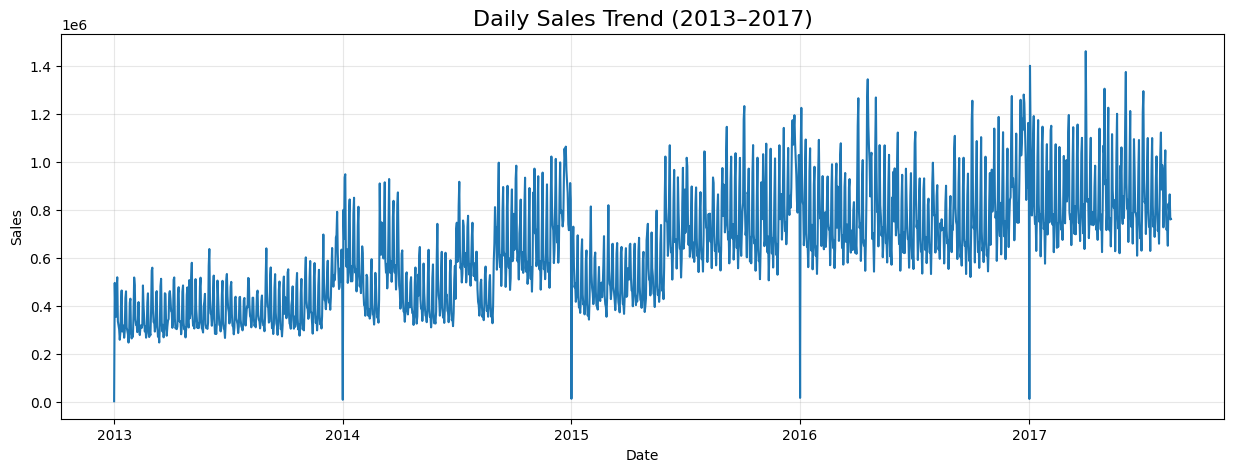

In [18]:
# Daily Sales Trend

plt.figure(figsize=(15,5))

plt.plot(daily_sales["date"], daily_sales["sales"])

plt.title("Daily Sales Trend (2013–2017)", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Sales")

plt.grid(alpha=0.3)

plt.show()

### Code Explanation

This section aggregates daily sales across all stores and product families to visualize the overall historical sales trend during the available period.


### Executive Conclusion

The daily sales trend provides the baseline behavior of the business and helps identify long-term growth, seasonal fluctuations, and unusual demand spikes that may affect forecasting performance.


## Monthly Sales Trend

In [19]:
# ============================================
# Monthly Sales Trend
# ============================================

monthly_sales = daily_sales.copy()

monthly_sales["YearMonth"] = (
    monthly_sales["date"]
    .dt.to_period("M")
    .astype(str)
)

monthly_sales = (
    monthly_sales
    .groupby("YearMonth")["sales"]
    .sum()
    .reset_index()
)

monthly_sales.head()

,YearMonth,sales
0,2013-01,1.032762e+07
1,2013-02,9.658960e+06
2,2013-03,1.142850e+07
3,2013-04,1.099346e+07
4,2013-05,1.159770e+07


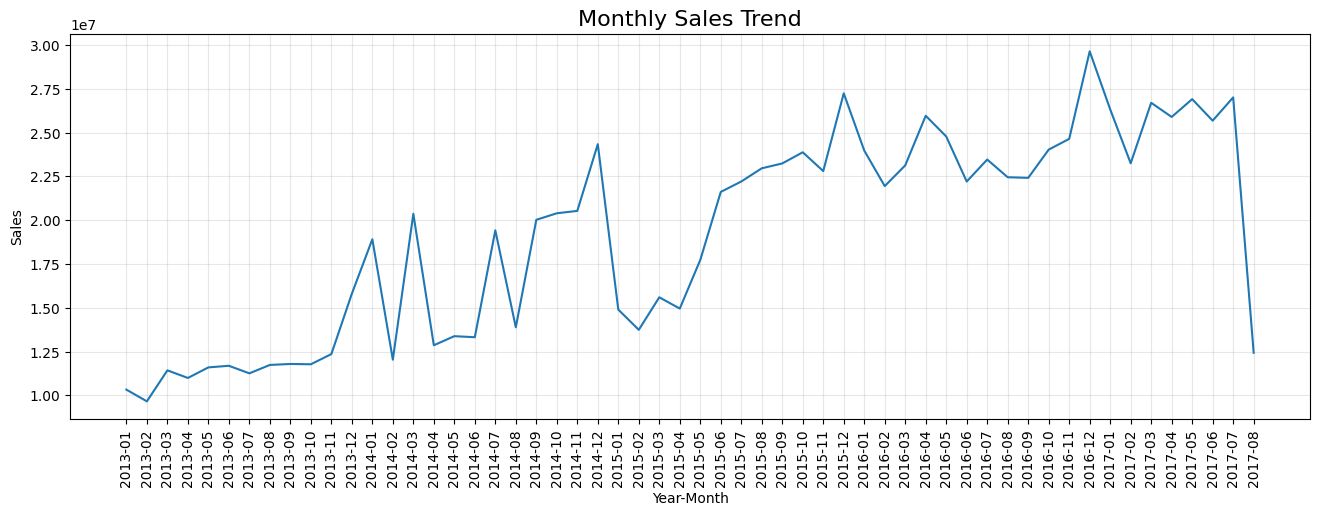

In [20]:
plt.figure(figsize=(16,5))

plt.plot(monthly_sales["YearMonth"], monthly_sales["sales"])

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Year-Month")
plt.ylabel("Sales")

plt.xticks(rotation=90)

plt.grid(alpha=0.3)

plt.show()

### Code Explanation

This section aggregates daily sales into monthly revenue to identify long-term seasonality and commercial demand patterns throughout the historical period.


### Executive Conclusion

Monthly aggregation helps identify recurring seasonal peaks and demand cycles that will later become forecasting features.


## Top Product Families

In [21]:
# ============================================
# Top Product Families
# ============================================

family_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

family_sales.head(10)

,family,sales
0,GROCERY I,3.434627e+08
1,BEVERAGES,2.169545e+08
2,PRODUCE,1.227047e+08
3,CLEANING,9.752129e+07
4,DAIRY,6.448771e+07
5,BREAD/BAKERY,4.213395e+07
6,POULTRY,3.187600e+07
7,MEATS,3.108647e+07
8,PERSONAL CARE,2.459205e+07
9,DELI,2.411032e+07


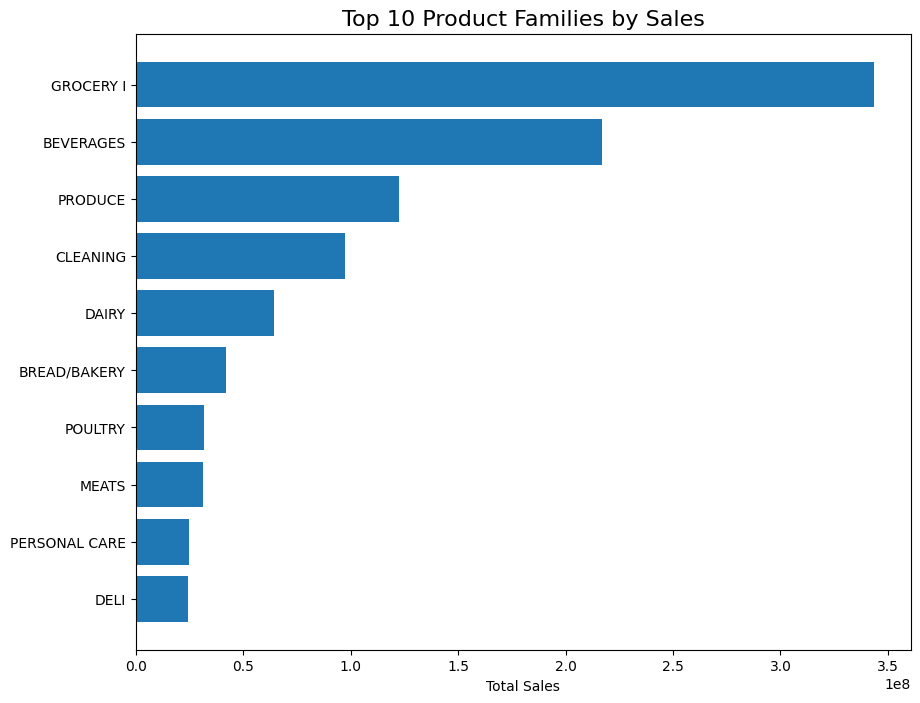

In [22]:
plt.figure(figsize=(10,8))

plt.barh(
    family_sales.head(10)["family"],
    family_sales.head(10)["sales"]
)

plt.title("Top 10 Product Families by Sales", fontsize=16)

plt.xlabel("Total Sales")

plt.gca().invert_yaxis()

plt.show()

### Code Explanation

This section identifies the product families generating the highest sales volume across the retail network.


### Executive Conclusion

Identifying the highest-selling product families helps prioritize forecasting efforts on the categories with the greatest commercial impact.


## Top Stores by Sales


In [23]:
# ============================================
# Top Stores by Sales
# ============================================

store_sales = (
    train.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

store_sales.head(10)

,store_nbr,sales
0,44,6.208755e+07
1,45,5.449801e+07
2,47,5.094831e+07
3,3,5.048191e+07
4,49,4.342010e+07
5,46,4.189606e+07
6,48,3.593313e+07
7,51,3.291149e+07
8,8,3.049429e+07
9,50,2.865302e+07


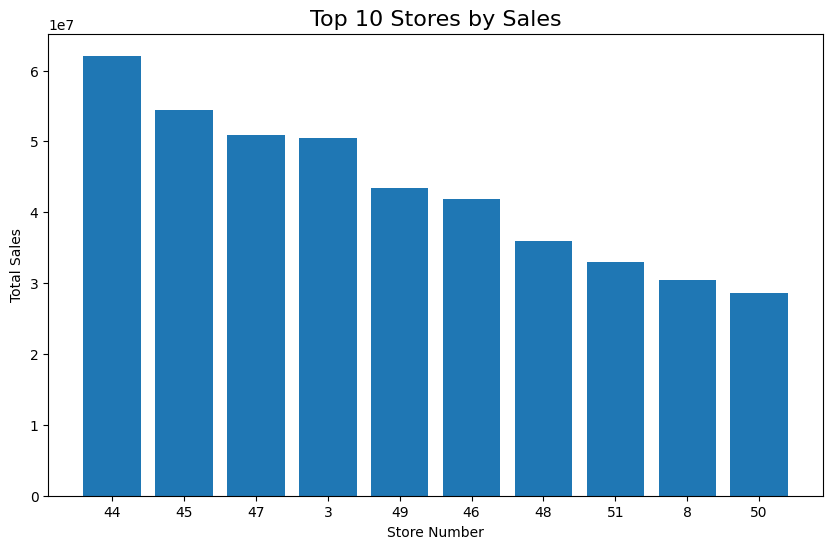

In [24]:
plt.figure(figsize=(10,6))

plt.bar(
    store_sales.head(10)["store_nbr"].astype(str),
    store_sales.head(10)["sales"]
)

plt.title("Top 10 Stores by Sales", fontsize=16)
plt.xlabel("Store Number")
plt.ylabel("Total Sales")

plt.show()

### Code Explanation

This section ranks retail stores according to total sales generated during the historical period.


### Executive Conclusion

Store-level performance helps identify strategic locations that contribute the largest share of revenue and require higher forecasting accuracy.


## Promotion Impact

In [25]:
# ============================================
# Promotion Impact
# ============================================

promotion_sales = (
    train.groupby("onpromotion")["sales"]
    .mean()
    .reset_index()
)

promotion_sales.head(10)

,onpromotion,sales
0,0,158.246681
1,1,467.556532
2,2,662.925632
3,3,871.408092
4,4,969.916135
5,5,1010.659835
6,6,1022.854287
7,7,1022.567058
8,8,1174.757003
9,9,1258.733993


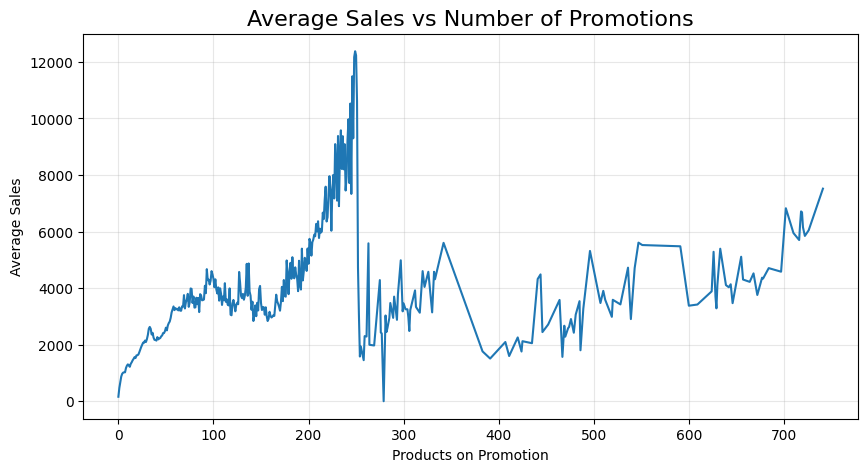

In [26]:
plt.figure(figsize=(10,5))

plt.plot(
    promotion_sales["onpromotion"],
    promotion_sales["sales"]
)

plt.title("Average Sales vs Number of Promotions", fontsize=16)

plt.xlabel("Products on Promotion")
plt.ylabel("Average Sales")

plt.grid(alpha=0.3)

plt.show()

### Code Explanation

This section analyzes the relationship between promotional intensity and average sales performance.


### Executive Conclusion

Promotional activity is expected to be one of the strongest predictors of demand and will become an important forecasting feature in the modeling stage.


## Top Stores by Sales

In [27]:
# ============================================
# Top Stores by Sales
# ============================================

store_sales = (
    train.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

store_sales.head(10)

,store_nbr,sales
0,44,6.208755e+07
1,45,5.449801e+07
2,47,5.094831e+07
3,3,5.048191e+07
4,49,4.342010e+07
5,46,4.189606e+07
6,48,3.593313e+07
7,51,3.291149e+07
8,8,3.049429e+07
9,50,2.865302e+07


### Code Explanation

This section ranks retail stores based on total historical sales to identify the locations with the highest commercial contribution.


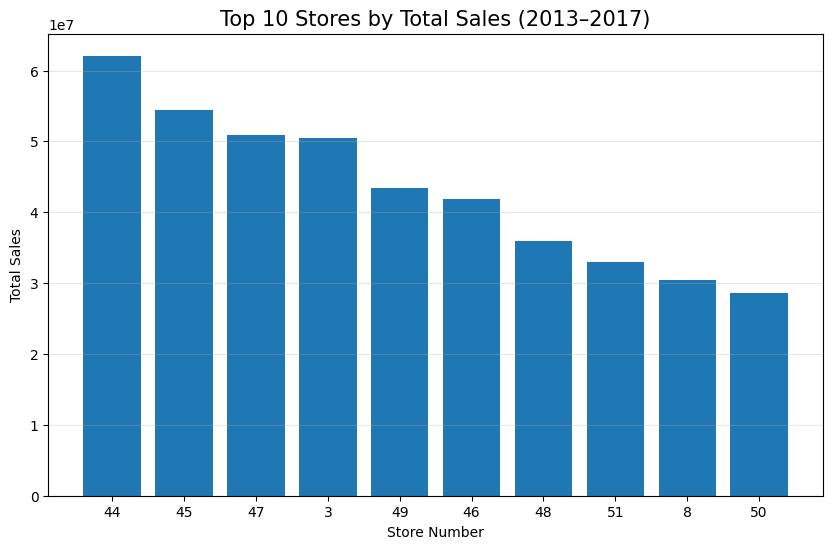

In [28]:
# ============================================
# Top 10 Stores Visualization
# ============================================

plt.figure(figsize=(10,6))

plt.bar(
    store_sales.head(10)["store_nbr"].astype(str),
    store_sales.head(10)["sales"]
)

plt.title("Top 10 Stores by Total Sales (2013–2017)", fontsize=15)
plt.xlabel("Store Number")
plt.ylabel("Total Sales")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Code Explanation

This visualization highlights the ten retail stores that generated the highest total sales during the historical period. Ranking stores by revenue helps identify the locations with the greatest commercial contribution and forecasting priority.


### Executive Conclusion

A small group of stores contributes a significant portion of total revenue across the retail network. These high-performing locations should receive greater forecasting attention because inventory shortages or forecast errors would have a larger commercial impact.


## Promotion Impact Analysis

In [29]:
# ============================================
# Promotion Impact Analysis
# ============================================

promotion_sales = (
    train.groupby("onpromotion")["sales"]
    .mean()
    .reset_index()
)

promotion_sales.head(15)

,onpromotion,sales
0,0,158.246681
1,1,467.556532
2,2,662.925632
3,3,871.408092
4,4,969.916135
5,5,1010.659835
6,6,1022.854287
7,7,1022.567058
8,8,1174.757003
9,9,1258.733993


### Code Explanation

This section analyzes the relationship between promotional activity and average sales performance across all stores and product families.


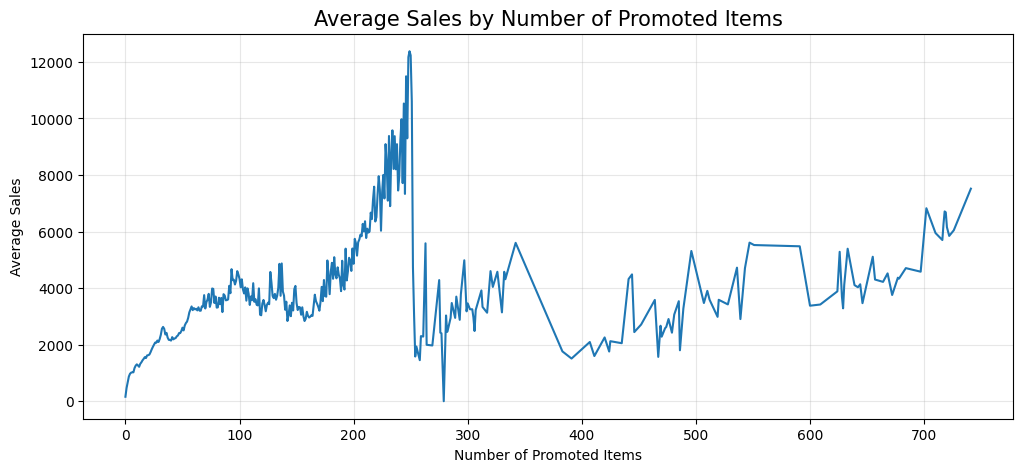

In [30]:
# ============================================
# Promotion Impact Visualization
# ============================================

plt.figure(figsize=(12,5))

plt.plot(
    promotion_sales["onpromotion"],
    promotion_sales["sales"]
)

plt.title("Average Sales by Number of Promoted Items", fontsize=15)
plt.xlabel("Number of Promoted Items")
plt.ylabel("Average Sales")

plt.grid(alpha=0.3)

plt.show()

### Executive Conclusion

Promotional activity shows a positive relationship with average sales and represents a key commercial driver of demand. The `onpromotion` variable will be included as one of the most important forecasting features in the predictive model.


## Sales Distribution Analysis

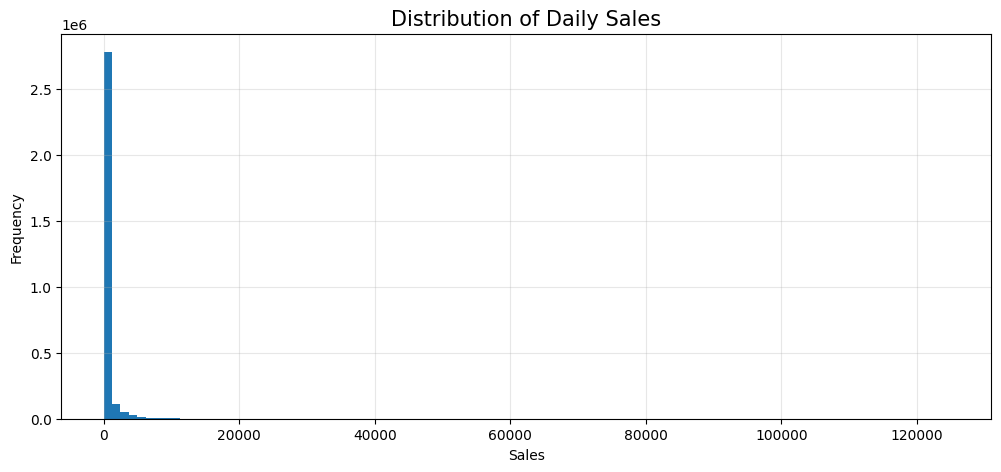

In [31]:
# ============================================
# Sales Distribution
# ============================================

plt.figure(figsize=(12,5))

plt.hist(train["sales"], bins=100)

plt.title("Distribution of Daily Sales", fontsize=15)
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

### Code Explanation

This section visualizes the distribution of daily sales to understand the variability of the target variable and identify potential outliers before forecasting.


### Executive Conclusion

Daily sales are highly right-skewed, meaning most observations have relatively low sales while a smaller number of transactions generate very high sales volumes. This distribution suggests that forecasting models should account for demand variability and potential outliers.


## Sales by Product Family

In [32]:
# ============================================
# Sales by Product Family
# ============================================

family_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

family_sales.head(10)

,family,sales
0,GROCERY I,3.434627e+08
1,BEVERAGES,2.169545e+08
2,PRODUCE,1.227047e+08
3,CLEANING,9.752129e+07
4,DAIRY,6.448771e+07
5,BREAD/BAKERY,4.213395e+07
6,POULTRY,3.187600e+07
7,MEATS,3.108647e+07
8,PERSONAL CARE,2.459205e+07
9,DELI,2.411032e+07


### Code Explanation

This section aggregates historical sales by product family to identify the categories with the highest commercial contribution across the retail network.


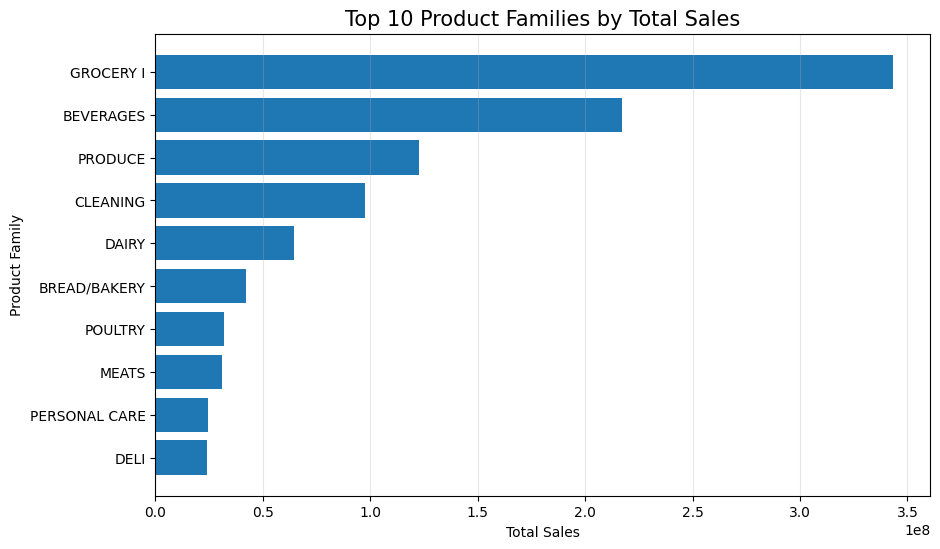

In [33]:
# ============================================
# Top Product Families Visualization
# ============================================

top10_family = family_sales.head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top10_family["family"],
    top10_family["sales"]
)

plt.title("Top 10 Product Families by Total Sales", fontsize=15)
plt.xlabel("Total Sales")
plt.ylabel("Product Family")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

### Executive Conclusion

A limited number of product families generate the largest share of total sales across the retail business. These categories should receive greater forecasting attention because they have the highest impact on revenue, inventory allocation, and commercial planning.


## Sales by Store Type

In [34]:
# ============================================
# Merge Sales with Store Information
# ============================================

sales_store = train.merge(
    stores,
    on="store_nbr",
    how="left"
)

sales_store.head()

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13


### Code Explanation

This section combines sales transactions with store information, enriching the dataset with geographic and operational attributes for each retail location.


In [35]:
# ============================================
# Sales by Store Type
# ============================================

sales_by_type = (
    sales_store.groupby("type")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

sales_by_type

,type,sales
0,A,3.530438e+08
1,D,3.510833e+08
2,C,1.644347e+08
3,B,1.452606e+08
4,E,5.982244e+07


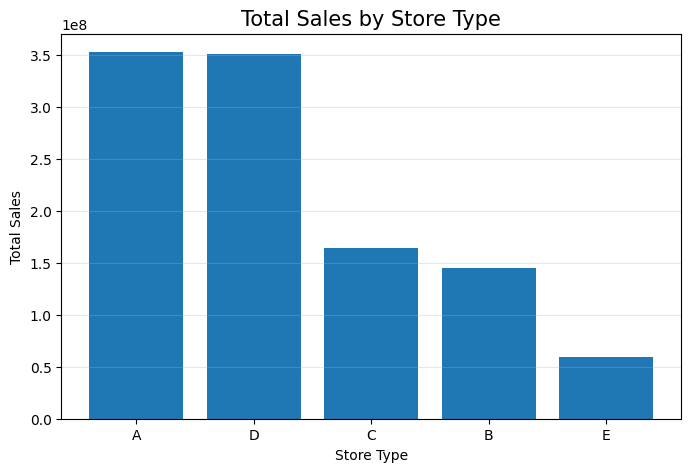

In [36]:
# ============================================
# Store Type Visualization
# ============================================

plt.figure(figsize=(8,5))

plt.bar(
    sales_by_type["type"],
    sales_by_type["sales"]
)

plt.title("Total Sales by Store Type", fontsize=15)
plt.xlabel("Store Type")
plt.ylabel("Total Sales")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Executive Conclusion

Store types contribute differently to total revenue, indicating that demand behavior varies across retail formats. Store type will be considered a valuable feature for segmentation and forecasting models.


## Sales by City

In [37]:
# ============================================
# Sales by City
# ============================================

city_sales = (
    sales_store.groupby("city")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

city_sales.head(10)

,city,sales
0,Quito,5.567418e+08
1,Guayaquil,1.229673e+08
2,Cuenca,4.916860e+07
3,Ambato,4.030440e+07
4,Santo Domingo,3.583432e+07
5,Machala,3.338680e+07
6,Cayambe,2.832556e+07
7,Latacunga,2.118226e+07
8,Daule,1.918802e+07
9,Loja,1.886000e+07


### Code Explanation

This section aggregates total sales by city to identify the geographic markets with the highest commercial contribution across the retail network.


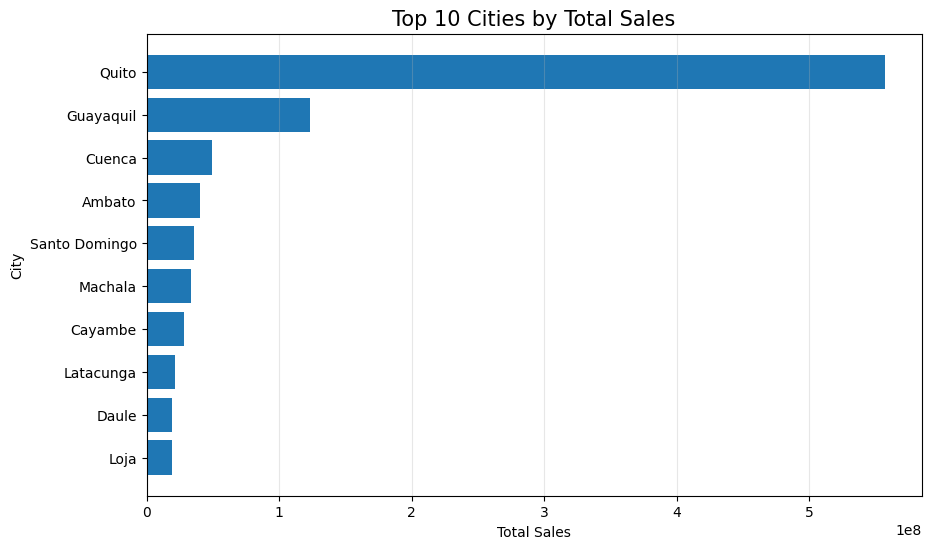

In [38]:
# ============================================
# Top 10 Cities Visualization
# ============================================

top10_city = city_sales.head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top10_city["city"],
    top10_city["sales"]
)

plt.title("Top 10 Cities by Total Sales", fontsize=15)
plt.xlabel("Total Sales")
plt.ylabel("City")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

### Executive Conclusion

Sales are concentrated in a small number of cities, indicating that the business has stronger commercial presence in specific geographic markets. These locations should be prioritized for inventory planning and demand forecasting because they represent the largest revenue opportunities.


## Sales by State

In [39]:
# ============================================
# Sales by State
# ============================================

state_sales = (
    sales_store.groupby("state")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

state_sales

,state,sales
0,Pichincha,5.850674e+08
1,Guayas,1.651544e+08
2,Azuay,4.916860e+07
3,Tungurahua,4.030440e+07
4,Santo Domingo de los Tsachilas,3.583432e+07
5,El Oro,3.338680e+07
6,Los Rios,3.192537e+07
7,Manabi,2.496982e+07
8,Cotopaxi,2.118226e+07
9,Loja,1.886000e+07


### Code Explanation

This section aggregates historical sales by state to identify the regions with the highest commercial contribution across the retail network.

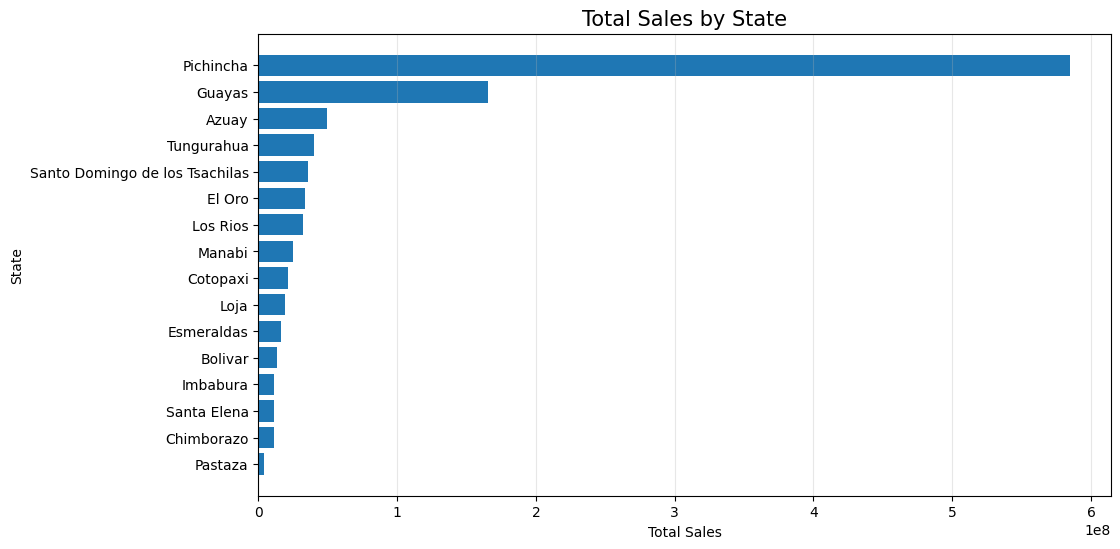

In [40]:
# ============================================
# State Sales Visualization
# ============================================

plt.figure(figsize=(11,6))

plt.barh(
    state_sales["state"],
    state_sales["sales"]
)

plt.title("Total Sales by State", fontsize=15)
plt.xlabel("Total Sales")
plt.ylabel("State")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

### Executive Conclusion

Sales performance is uneven across states, indicating that commercial demand is concentrated in specific regions. Geographic segmentation can improve inventory allocation, sales planning, and regional demand forecasting.

## Sales by Store Cluster

In [41]:
# ============================================
# Sales by Store Cluster
# ============================================

cluster_sales = (
    sales_store.groupby("cluster")["sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

cluster_sales

,cluster,sales
0,14,1.574305e+08
1,6,1.142544e+08
2,8,1.079282e+08
3,11,1.006143e+08
4,10,8.532443e+07
5,3,7.562870e+07
6,13,7.210225e+07
7,5,6.208755e+07
8,15,5.529695e+07
9,1,5.437675e+07


### Code Explanation

This section groups historical sales by store cluster to identify commercial segments with similar demand behavior and revenue contribution.


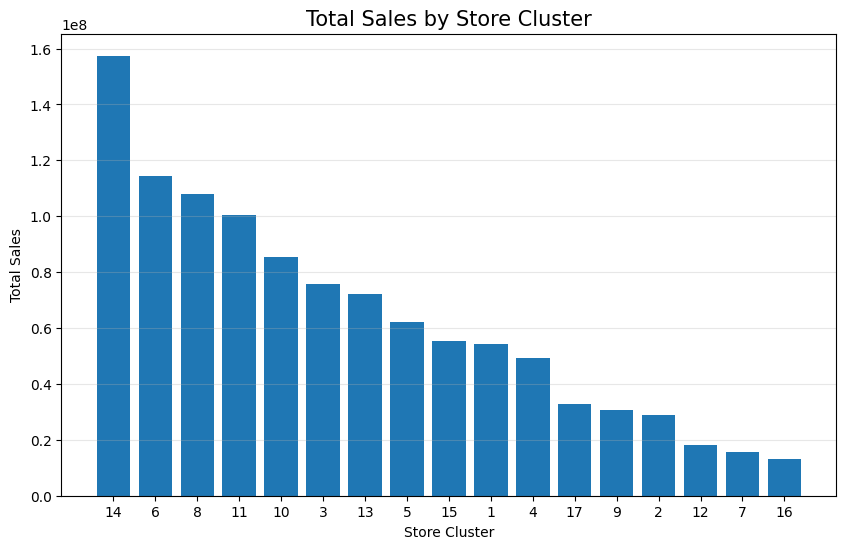

In [42]:
# ============================================
# Cluster Sales Visualization
# ============================================

plt.figure(figsize=(10,6))

plt.bar(
    cluster_sales["cluster"].astype(str),
    cluster_sales["sales"]
)

plt.title("Total Sales by Store Cluster", fontsize=15)
plt.xlabel("Store Cluster")
plt.ylabel("Total Sales")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Business Insight

Store clusters represent groups of retail locations with similar operational and commercial characteristics. Comparing sales by cluster helps identify segments that may require different inventory and forecasting strategies.


### Executive Conclusion

Sales performance varies across store clusters, suggesting that demand patterns are influenced by store segmentation. Cluster information will be incorporated into the forecasting model as a categorical feature to improve prediction accuracy.


## Transactions vs Sales Analysis

In [43]:
# ============================================
# Merge Sales with Transactions
# ============================================

daily_store_sales = (
    train.groupby(["date", "store_nbr"])["sales"]
    .sum()
    .reset_index()
)

sales_transactions = daily_store_sales.merge(
    transactions,
    on=["date", "store_nbr"],
    how="left"
)

sales_transactions.head()

,date,store_nbr,sales,transactions
0,2013-01-01,1,0.0,NaN
1,2013-01-01,2,0.0,NaN
2,2013-01-01,3,0.0,NaN
3,2013-01-01,4,0.0,NaN
4,2013-01-01,5,0.0,NaN


### Code Explanation

This section combines daily sales with the number of customer transactions for each store and date, allowing us to evaluate the relationship between customer traffic and sales performance.


In [44]:
# ============================================
# Correlation between Sales and Transactions
# ============================================

correlation = sales_transactions[["sales", "transactions"]].corr()

correlation

,sales,transactions
sales,1.000000,0.837384
transactions,0.837384,1.000000


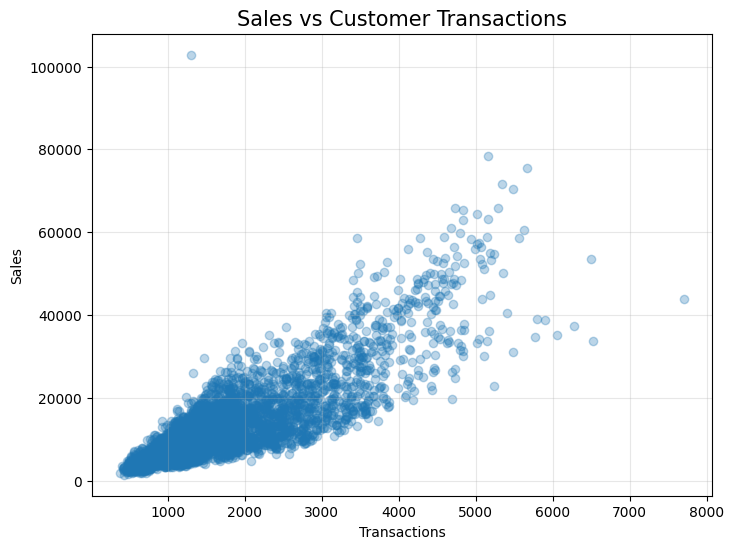

In [45]:
# ============================================
# Scatter Plot: Transactions vs Sales
# ============================================

sample = sales_transactions.sample(5000, random_state=42)

plt.figure(figsize=(8,6))

plt.scatter(
    sample["transactions"],
    sample["sales"],
    alpha=0.3
)

plt.title("Sales vs Customer Transactions", fontsize=15)
plt.xlabel("Transactions")
plt.ylabel("Sales")

plt.grid(alpha=0.3)

plt.show()

### Business Insight

Customer transactions represent store traffic and are expected to be strongly associated with daily sales. Understanding this relationship helps explain demand fluctuations across retail locations.


### Executive Conclusion

Customer traffic is an important driver of daily sales performance. The relationship between transactions and sales suggests that transaction volume can be used as an explanatory variable to improve demand forecasting models.


## Oil Price vs Sales Analysis

In [46]:
# ============================================
# Oil Price Preparation
# ============================================

oil = oil.sort_values("date")

# Fill missing oil prices using forward fill
oil["dcoilwtico"] = oil["dcoilwtico"].ffill()

oil.head()

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


### Code Explanation

This section prepares the oil price dataset by sorting dates and filling missing values using the previous available observation, ensuring a continuous time series.


In [47]:
# ============================================
# Merge Daily Sales with Oil Prices
# ============================================

sales_oil = daily_sales.merge(
    oil,
    on="date",
    how="left"
)

sales_oil.head()

,date,sales,dcoilwtico
0,2013-01-01,2511.618999,NaN
1,2013-01-02,496092.417944,93.14
2,2013-01-03,361461.231124,92.97
3,2013-01-04,354459.677093,93.12
4,2013-01-05,477350.121229,NaN


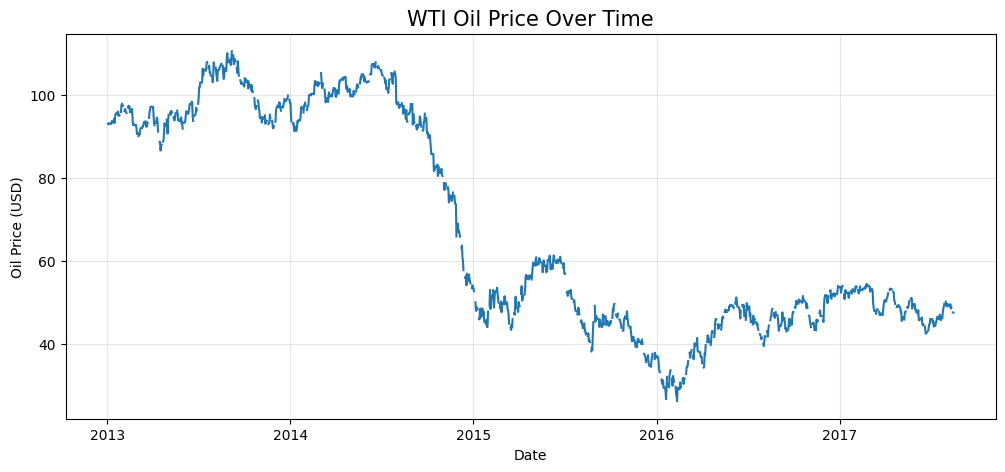

In [48]:
# ============================================
# Oil Price Trend
# ============================================

plt.figure(figsize=(12,5))

plt.plot(
    sales_oil["date"],
    sales_oil["dcoilwtico"]
)

plt.title("WTI Oil Price Over Time", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Oil Price (USD)")

plt.grid(alpha=0.3)

plt.show()

### Business Insight

Oil prices represent an external macroeconomic factor that may influence transportation costs, consumer spending, and retail demand over time.


### Executive Conclusion

Oil prices provide external market context that can improve demand forecasting by capturing macroeconomic changes affecting retail sales behavior.


## Holiday Impact on Sales

In [49]:
# ============================================
# Holiday Dataset Preparation
# ============================================

holidays_clean = holidays.copy()

# Keep only national holidays that were not transferred
holidays_clean = holidays_clean[
    (holidays_clean["locale"] == "National") &
    (holidays_clean["transferred"] == False)
]

holidays_clean = holidays_clean[["date", "type", "description"]]

holidays_clean.head()

,date,type,description
14,2012-08-10,Holiday,Primer Grito de Independencia
20,2012-10-12,Transfer,Traslado Independencia de Guayaquil
21,2012-11-02,Holiday,Dia de Difuntos
22,2012-11-03,Holiday,Independencia de Cuenca
31,2012-12-21,Additional,Navidad-4


### Code Explanation

This section filters the holiday dataset to retain official national holidays that directly affect retail demand across the country.

In [50]:
# ============================================
# Merge Sales with Holidays
# ============================================

sales_holidays = daily_sales.merge(
    holidays_clean,
    on="date",
    how="left"
)

sales_holidays["holiday_flag"] = sales_holidays["description"].notna()

sales_holidays.head()

,date,sales,type,description,holiday_flag
0,2013-01-01,2511.618999,Holiday,Primer dia del ano,True
1,2013-01-02,496092.417944,NaN,NaN,False
2,2013-01-03,361461.231124,NaN,NaN,False
3,2013-01-04,354459.677093,NaN,NaN,False
4,2013-01-05,477350.121229,Work Day,Recupero puente Navidad,True


In [51]:
# ============================================
# Holiday vs Non-Holiday Sales
# ============================================

holiday_comparison = (
    sales_holidays.groupby("holiday_flag")["sales"]
    .mean()
    .reset_index()
)

holiday_comparison

,holiday_flag,sales
0,False,627918.111596
1,True,754728.232374


### Code Explanation

This section compares average daily sales on holidays versus regular business days to measure the commercial impact of holidays.

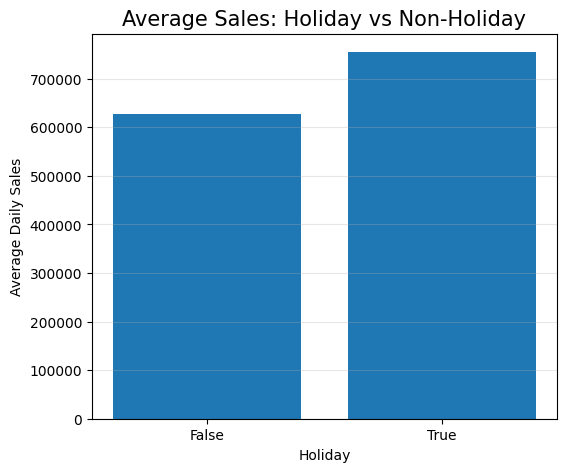

In [52]:
# ============================================
# Holiday Impact Visualization
# ============================================

plt.figure(figsize=(6,5))

plt.bar(
    holiday_comparison["holiday_flag"].astype(str),
    holiday_comparison["sales"]
)

plt.title("Average Sales: Holiday vs Non-Holiday", fontsize=15)
plt.xlabel("Holiday")
plt.ylabel("Average Daily Sales")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Business Insight

Holidays are expected to modify consumer purchasing behavior and generate demand spikes in several retail categories, making them an important calendar feature for forecasting.

### Executive Conclusion

National holidays create measurable changes in daily sales performance and should be incorporated as calendar-based features in the demand forecasting model.

# Module 4 — Feature Engineering

## Calendar Features

In [53]:
# ============================================
# Calendar Feature Engineering
# ============================================

train_fe = train.copy()

train_fe["year"] = train_fe["date"].dt.year
train_fe["month"] = train_fe["date"].dt.month
train_fe["day"] = train_fe["date"].dt.day
train_fe["day_of_week"] = train_fe["date"].dt.dayofweek
train_fe["week_of_year"] = train_fe["date"].dt.isocalendar().week.astype(int)
train_fe["quarter"] = train_fe["date"].dt.quarter

train_fe.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,1,1
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,1,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,1,1
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,1,1


### Code Explanation

This section creates calendar-based features from the date variable. These variables help forecasting models capture seasonality, monthly trends, quarterly behavior, and weekly demand patterns.

In [54]:
# ============================================
# Validate Calendar Features
# ============================================

train_fe[
    [
        "date",
        "year",
        "month",
        "day",
        "day_of_week",
        "week_of_year",
        "quarter"
    ]
].head(10)

,date,year,month,day,day_of_week,week_of_year,quarter
0,2013-01-01,2013,1,1,1,1,1
1,2013-01-01,2013,1,1,1,1,1
2,2013-01-01,2013,1,1,1,1,1
3,2013-01-01,2013,1,1,1,1,1
4,2013-01-01,2013,1,1,1,1,1
5,2013-01-01,2013,1,1,1,1,1
6,2013-01-01,2013,1,1,1,1,1
7,2013-01-01,2013,1,1,1,1,1
8,2013-01-01,2013,1,1,1,1,1
9,2013-01-01,2013,1,1,1,1,1


### Business Insight

Retail demand is strongly influenced by calendar effects such as weekdays, weekends, months, and seasonal periods. Calendar variables allow forecasting models to learn recurring purchasing patterns over time.

### Executive Conclusion

Calendar features transform the date column into meaningful business variables that capture seasonality and demand cycles, providing the foundation for accurate time-series forecasting models.

## Weekend Feature Engineering

In [55]:
# ============================================
# Weekend Feature
# ============================================

train_fe["is_weekend"] = train_fe["day_of_week"].isin([5, 6])

train_fe[["date", "day_of_week", "is_weekend"]].head(10)

,date,day_of_week,is_weekend
0,2013-01-01,1,False
1,2013-01-01,1,False
2,2013-01-01,1,False
3,2013-01-01,1,False
4,2013-01-01,1,False
5,2013-01-01,1,False
6,2013-01-01,1,False
7,2013-01-01,1,False
8,2013-01-01,1,False
9,2013-01-01,1,False


### Code Explanation

This section creates a binary feature that identifies weekends. Weekend purchasing behavior is often different from weekday demand in retail forecasting.


In [56]:
# ============================================
# Weekend Sales Comparison
# ============================================

weekend_sales = (
    train_fe.groupby("is_weekend")["sales"]
    .mean()
    .reset_index()
)

weekend_sales

,is_weekend,sales
0,False,321.629081
1,True,448.179995


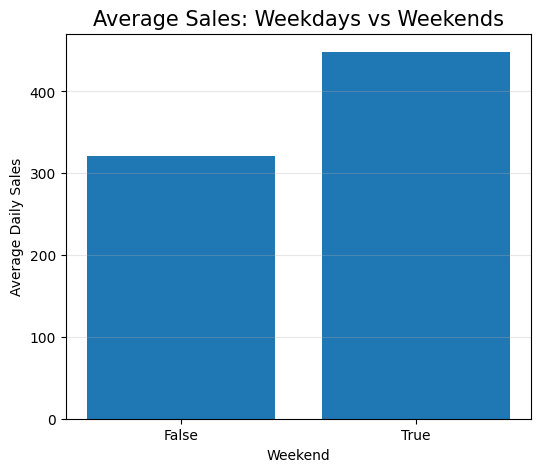

In [57]:
# ============================================
# Weekend Sales Visualization
# ============================================

plt.figure(figsize=(6,5))

plt.bar(
    weekend_sales["is_weekend"].astype(str),
    weekend_sales["sales"]
)

plt.title("Average Sales: Weekdays vs Weekends", fontsize=15)
plt.xlabel("Weekend")
plt.ylabel("Average Daily Sales")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Business Insight

Customer purchasing behavior often changes during weekends due to shopping habits, promotions, and increased retail traffic.


### Executive Conclusion

Weekend behavior represents a recurring seasonal pattern in retail demand. The `is_weekend` feature will help the forecasting model distinguish weekday demand from weekend demand.


## Lag Features

In [58]:
# ============================================
# Sort Dataset Before Creating Lags
# ============================================

train_fe = train_fe.sort_values(
    by=["store_nbr", "family", "date"]
).reset_index(drop=True)

train_fe.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,False
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,2,1,1,False
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,3,1,1,False
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,4,1,1,False
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,5,1,1,True


### Code Explanation

This section sorts the dataset by store, product family, and date to preserve the chronological order required for time-series feature engineering.


In [59]:
# ============================================
# Lag Feature - Previous Day Sales
# ============================================

train_fe["lag_1"] = (
    train_fe.groupby(["store_nbr", "family"])["sales"]
    .shift(1)
)

train_fe[
    ["date", "store_nbr", "family", "sales", "lag_1"]
].head(10)

,date,store_nbr,family,sales,lag_1
0,2013-01-01,1,AUTOMOTIVE,0.0,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,0.0
2,2013-01-03,1,AUTOMOTIVE,3.0,2.0
3,2013-01-04,1,AUTOMOTIVE,3.0,3.0
4,2013-01-05,1,AUTOMOTIVE,5.0,3.0
5,2013-01-06,1,AUTOMOTIVE,2.0,5.0
6,2013-01-07,1,AUTOMOTIVE,0.0,2.0
7,2013-01-08,1,AUTOMOTIVE,2.0,0.0
8,2013-01-09,1,AUTOMOTIVE,2.0,2.0
9,2013-01-10,1,AUTOMOTIVE,2.0,2.0


### Code Explanation

This feature captures the sales value from the previous day for each store and product family, allowing the forecasting model to learn short-term demand continuity.


In [60]:
# ============================================
# Lag Feature - Previous Week Sales
# ============================================

train_fe["lag_7"] = (
    train_fe.groupby(["store_nbr", "family"])["sales"]
    .shift(7)
)

train_fe[
    ["date", "sales", "lag_1", "lag_7"]
].head(15)

,date,sales,lag_1,lag_7
0,2013-01-01,0.0,NaN,NaN
1,2013-01-02,2.0,0.0,NaN
2,2013-01-03,3.0,2.0,NaN
3,2013-01-04,3.0,3.0,NaN
4,2013-01-05,5.0,3.0,NaN
5,2013-01-06,2.0,5.0,NaN
6,2013-01-07,0.0,2.0,NaN
7,2013-01-08,2.0,0.0,0.0
8,2013-01-09,2.0,2.0,2.0
9,2013-01-10,2.0,2.0,3.0


### Code Explanation

The seven-day lag captures weekly demand repetition, helping the model recognize recurring weekly purchasing patterns.


In [61]:
# ============================================
# Lag Feature - Previous Month Sales
# ============================================

train_fe["lag_30"] = (
    train_fe.groupby(["store_nbr", "family"])["sales"]
    .shift(30)
)

train_fe[
    ["date", "sales", "lag_1", "lag_7", "lag_30"]
].head(35)

,date,sales,lag_1,lag_7,lag_30
0,2013-01-01,0.0,NaN,NaN,NaN
1,2013-01-02,2.0,0.0,NaN,NaN
2,2013-01-03,3.0,2.0,NaN,NaN
3,2013-01-04,3.0,3.0,NaN,NaN
4,2013-01-05,5.0,3.0,NaN,NaN
...,...,...,...,...,...
30,2013-01-31,0.0,6.0,0.0,0.0
31,2013-02-01,3.0,0.0,5.0,2.0
32,2013-02-02,0.0,3.0,4.0,3.0
33,2013-02-03,0.0,0.0,2.0,3.0


### Code Explanation

The thirty-day lag captures monthly demand memory, allowing the model to identify recurring monthly purchasing behavior.


In [62]:
# ============================================
# Missing Values Generated by Lag Features
# ============================================

lag_missing = train_fe[
    ["lag_1", "lag_7", "lag_30"]
].isna().sum().to_frame(name="Missing Values")

lag_missing

,Missing Values
lag_1,1782
lag_7,12474
lag_30,53460


### Code Explanation

Lag features naturally generate missing values at the beginning of each time series because historical observations are unavailable for previous periods.


### Business Insight

Historical sales are one of the strongest predictors of future demand because retail purchasing behavior tends to repeat over short, weekly, and monthly horizons.


### Executive Conclusion

Lag features introduce historical demand memory into the forecasting dataset, enabling predictive models to capture short-term and seasonal sales behavior more accurately.


## Rolling Average Features

In [63]:
# ============================================
# Rolling Average - Last 7 Days
# ============================================

train_fe["rolling_mean_7"] = (
    train_fe.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

train_fe[
    ["date", "sales", "lag_1", "rolling_mean_7"]
].head(15)

,date,sales,lag_1,rolling_mean_7
0,2013-01-01,0.0,NaN,NaN
1,2013-01-02,2.0,0.0,NaN
2,2013-01-03,3.0,2.0,NaN
3,2013-01-04,3.0,3.0,NaN
4,2013-01-05,5.0,3.0,NaN
5,2013-01-06,2.0,5.0,NaN
6,2013-01-07,0.0,2.0,NaN
7,2013-01-08,2.0,0.0,2.142857
8,2013-01-09,2.0,2.0,2.428571
9,2013-01-10,2.0,2.0,2.428571


### Code Explanation

This section creates a seven-day rolling average of historical sales for each store and product family. The current day is excluded to prevent data leakage during forecasting.


In [64]:
# ============================================
# Rolling Average - Last 14 Days
# ============================================

train_fe["rolling_mean_14"] = (
    train_fe.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=14).mean())
)

train_fe[
    ["date", "sales", "rolling_mean_7", "rolling_mean_14"]
].head(20)

,date,sales,rolling_mean_7,rolling_mean_14
0,2013-01-01,0.0,NaN,NaN
1,2013-01-02,2.0,NaN,NaN
2,2013-01-03,3.0,NaN,NaN
3,2013-01-04,3.0,NaN,NaN
4,2013-01-05,5.0,NaN,NaN
5,2013-01-06,2.0,NaN,NaN
6,2013-01-07,0.0,NaN,NaN
7,2013-01-08,2.0,2.142857,NaN
8,2013-01-09,2.0,2.428571,NaN
9,2013-01-10,2.0,2.428571,NaN


### Code Explanation

This feature captures the average sales behavior over the previous two weeks, helping the model recognize medium-term demand trends.


In [65]:
# ============================================
# Rolling Average - Last 30 Days
# ============================================

train_fe["rolling_mean_30"] = (
    train_fe.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=30).mean())
)

train_fe[
    ["date", "sales", "rolling_mean_7", "rolling_mean_14", "rolling_mean_30"]
].head(35)

,date,sales,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,2013-01-01,0.0,NaN,NaN,NaN
1,2013-01-02,2.0,NaN,NaN,NaN
2,2013-01-03,3.0,NaN,NaN,NaN
3,2013-01-04,3.0,NaN,NaN,NaN
4,2013-01-05,5.0,NaN,NaN,NaN
...,...,...,...,...,...
30,2013-01-31,0.0,3.142857,2.571429,2.266667
31,2013-02-01,3.0,3.142857,2.500000,2.266667
32,2013-02-02,0.0,2.857143,2.714286,2.300000
33,2013-02-03,0.0,2.285714,2.357143,2.200000


### Code Explanation

The thirty-day rolling average summarizes monthly sales behavior and smooths daily fluctuations, providing a longer-term demand trend for forecasting.


In [66]:
# ============================================
# Missing Values from Rolling Features
# ============================================

rolling_missing = train_fe[
    ["rolling_mean_7", "rolling_mean_14", "rolling_mean_30"]
].isna().sum().to_frame(name="Missing Values")

rolling_missing

,Missing Values
rolling_mean_7,12474
rolling_mean_14,24948
rolling_mean_30,53460


### Code Explanation

Rolling averages require historical observations, so missing values naturally appear at the beginning of each time series.


### Business Insight

Rolling averages reduce daily volatility and reveal recent demand trends, making them valuable predictors for retail demand forecasting.


### Executive Conclusion

Rolling average features capture short-, medium-, and long-term demand trends while reducing noise in daily sales. These variables improve forecasting models by providing historical demand context beyond individual lag values.


## Integrating External Features

In [67]:
# ============================================
# Merge Transactions
# ============================================

train_fe = train_fe.merge(
    transactions,
    on=["date", "store_nbr"],
    how="left"
)

train_fe.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,2,1,1,False,0.0,NaN,NaN,NaN,NaN,NaN,2111.0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,3,1,1,False,2.0,NaN,NaN,NaN,NaN,NaN,1833.0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,4,1,1,False,3.0,NaN,NaN,NaN,NaN,NaN,1863.0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,5,1,1,True,3.0,NaN,NaN,NaN,NaN,NaN,1509.0


### Code Explanation

This section merges daily customer transactions into the feature engineering dataset using date and store number as the business keys.


In [68]:
# ============================================
# Merge Oil Prices
# ============================================

train_fe = train_fe.merge(
    oil[["date", "dcoilwtico"]],
    on="date",
    how="left"
)

train_fe["dcoilwtico"] = train_fe["dcoilwtico"].ffill()

train_fe.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30,transactions,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,2,1,1,False,0.0,NaN,NaN,NaN,NaN,NaN,2111.0,93.14
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,3,1,1,False,2.0,NaN,NaN,NaN,NaN,NaN,1833.0,92.97
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,4,1,1,False,3.0,NaN,NaN,NaN,NaN,NaN,1863.0,93.12
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,5,1,1,True,3.0,NaN,NaN,NaN,NaN,NaN,1509.0,93.12


### Code Explanation

This section enriches the forecasting dataset with daily oil prices, providing an external macroeconomic feature for demand prediction.


In [69]:
# ============================================
# Merge Holiday Flag
# ============================================

holiday_flag = holidays_clean.copy()
holiday_flag["holiday_flag"] = True

train_fe = train_fe.merge(
    holiday_flag[["date", "holiday_flag"]],
    on="date",
    how="left"
)

train_fe["holiday_flag"] = train_fe["holiday_flag"].fillna(False)

train_fe.head()

C:\Users\pc\AppData\Local\Temp\ipykernel_13764\2887640893.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_fe["holiday_flag"] = train_fe["holiday_flag"].fillna(False)


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30,transactions,dcoilwtico,holiday_flag
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,2,1,1,False,0.0,NaN,NaN,NaN,NaN,NaN,2111.0,93.14,False
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,3,1,1,False,2.0,NaN,NaN,NaN,NaN,NaN,1833.0,92.97,False
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,4,1,1,False,3.0,NaN,NaN,NaN,NaN,NaN,1863.0,93.12,False
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,5,1,1,True,3.0,NaN,NaN,NaN,NaN,NaN,1509.0,93.12,True


### Code Explanation

This section creates a binary holiday indicator that identifies official national holidays affecting retail demand.


In [70]:
# ============================================
# Feature Engineering Dataset Summary
# ============================================

print("Rows and Columns:", train_fe.shape)

train_fe.info()

Rows and Columns: (3008016, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3008016 entries, 0 to 3008015
Data columns (total 22 columns):
 #   Column           Dtype         
---  ------           -----         
 0   id               int64         
 1   date             datetime64[ns]
 2   store_nbr        int64         
 3   family           object        
 4   sales            float64       
 5   onpromotion      int64         
 6   year             int32         
 7   month            int32         
 8   day              int32         
 9   day_of_week      int32         
 10  week_of_year     int64         
 11  quarter          int32         
 12  is_weekend       bool          
 13  lag_1            float64       
 14  lag_7            float64       
 15  lag_30           float64       
 16  rolling_mean_7   float64       
 17  rolling_mean_14  float64       
 18  rolling_mean_30  float64       
 19  transactions     float64       
 20  dcoilwtico       float64       
 21 

### Business Insight

Demand forecasting benefits from combining operational, promotional, temporal, and macroeconomic variables into a single analytical dataset. This integrated dataset captures multiple drivers of retail demand.


### Executive Conclusion

The forecasting dataset now integrates historical demand, customer traffic, promotional activity, holidays, and oil prices into a single feature engineering table. This dataset is ready for preprocessing and predictive modeling.


# Module 5 — Data Preprocessing

## Preparing the Forecasting Dataset

In [71]:
# ============================================
# Select Forecasting Features
# ============================================

forecast_dataset = train_fe[
    [
        "date",
        "store_nbr",
        "family",
        "sales",
        "onpromotion",
        "transactions",
        "dcoilwtico",
        "holiday_flag",
        "year",
        "month",
        "quarter",
        "week_of_year",
        "day_of_week",
        "is_weekend",
        "lag_1",
        "lag_7",
        "lag_30",
        "rolling_mean_7",
        "rolling_mean_14",
        "rolling_mean_30"
    ]
].copy()

forecast_dataset.head()

,date,store_nbr,family,sales,onpromotion,transactions,dcoilwtico,holiday_flag,year,month,quarter,week_of_year,day_of_week,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,2013-01-01,1,AUTOMOTIVE,0.0,0,NaN,NaN,True,2013,1,1,1,1,False,NaN,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,0,2111.0,93.14,False,2013,1,1,1,2,False,0.0,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.0,0,1833.0,92.97,False,2013,1,1,1,3,False,2.0,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.0,0,1863.0,93.12,False,2013,1,1,1,4,False,3.0,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.0,0,1509.0,93.12,True,2013,1,1,1,5,True,3.0,NaN,NaN,NaN,NaN,NaN


### Code Explanation

This section selects the final features that will be used for retail demand forecasting. The dataset combines temporal, commercial, operational, macroeconomic, and historical demand variables.


In [72]:
# ============================================
# Missing Values Review
# ============================================

missing_values = (
    forecast_dataset.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
)

missing_values.head(10)

,Missing Values
transactions,246081
rolling_mean_30,53460
lag_30,53460
rolling_mean_14,24948
lag_7,12474
rolling_mean_7,12474
lag_1,1782
dcoilwtico,1
sales,0
family,0


### Code Explanation

This section identifies missing values generated during feature engineering before preparing the dataset for predictive modeling.


In [73]:
# ============================================
# Remove Rows with Missing Lag Features
# ============================================

forecast_dataset = forecast_dataset.dropna().reset_index(drop=True)

print("Dataset Shape:", forecast_dataset.shape)

Dataset Shape: (2717880, 20)


### Code Explanation

Rows without sufficient historical information are removed to ensure that every observation contains complete forecasting features.


In [74]:
# ============================================
# Final Missing Values Validation
# ============================================

forecast_dataset.isna().sum()

date               0
store_nbr          0
family             0
sales              0
onpromotion        0
transactions       0
dcoilwtico         0
holiday_flag       0
year               0
month              0
quarter            0
week_of_year       0
day_of_week        0
is_weekend         0
lag_1              0
lag_7              0
lag_30             0
rolling_mean_7     0
rolling_mean_14    0
rolling_mean_30    0
dtype: int64

### Code Explanation

This validation confirms that the forecasting dataset is complete and ready for model training.


### Business Insight

Forecasting models require complete historical observations for every feature. Removing incomplete records ensures consistent training data and avoids biased predictions caused by missing historical demand information.


### Executive Conclusion

The forecasting dataset has been cleaned and standardized for predictive modeling. Every observation now contains complete temporal, commercial, operational, and historical demand features required for accurate retail forecasting.


In [75]:
# ============================================
# Save Processed Forecasting Dataset
# ============================================

forecast_dataset.to_csv(
    "../1. Data/Processed/forecast_dataset.csv",
    index=False
)

print("forecast_dataset.csv saved successfully!")

forecast_dataset.csv saved successfully!


### Code Explanation

This section exports the processed forecasting dataset, creating the official input file for machine learning models and Power BI dashboards.


# Module 6 — Forecasting Models

## Baseline Forecast Model

In [76]:
# ============================================
# Train / Validation Split
# ============================================

split_date = "2017-01-01"

train_set = forecast_dataset[
    forecast_dataset["date"] < split_date
].copy()

validation_set = forecast_dataset[
    forecast_dataset["date"] >= split_date
].copy()

print("Training Shape:", train_set.shape)
print("Validation Shape:", validation_set.shape)

Training Shape: (2318679, 20)
Validation Shape: (399201, 20)


### Code Explanation

This section splits the forecasting dataset chronologically into training and validation periods. Time order is preserved to simulate real-world forecasting conditions.

In [77]:
# ============================================
# Baseline Forecast
# ============================================

validation_set["baseline_prediction"] = validation_set["lag_1"]

validation_set[
    ["date", "sales", "baseline_prediction"]
].head()

,date,sales,baseline_prediction
1425,2017-01-02,5.0,0.0
1426,2017-01-03,4.0,5.0
1427,2017-01-04,1.0,4.0
1428,2017-01-05,2.0,1.0
1429,2017-01-06,2.0,2.0


### Code Explanation

The baseline model predicts today's sales using the previous day's sales. This naive approach establishes the minimum performance that every forecasting model should outperform.

In [78]:
# ============================================
# Mean Absolute Error (Baseline)
# ============================================

from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(
    validation_set["sales"],
    validation_set["baseline_prediction"]
)

print(f"Baseline MAE: {baseline_mae:.2f}")

Baseline MAE: 134.88


### Code Explanation

Mean Absolute Error (MAE) measures the average absolute difference between actual sales and predicted sales, making it one of the most interpretable forecasting metrics.

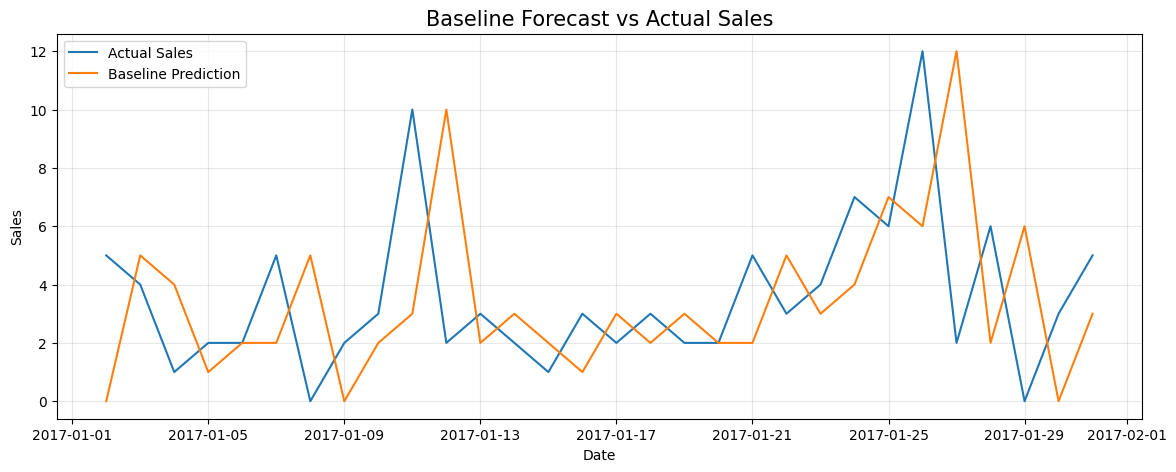

In [79]:
# ============================================
# Baseline Forecast Visualization
# ============================================

comparison = validation_set.head(30)

plt.figure(figsize=(14,5))

plt.plot(
    comparison["date"],
    comparison["sales"],
    label="Actual Sales"
)

plt.plot(
    comparison["date"],
    comparison["baseline_prediction"],
    label="Baseline Prediction"
)

plt.title("Baseline Forecast vs Actual Sales", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Business Insight

A baseline forecast provides a simple benchmark using historical demand memory. Any advanced forecasting model must demonstrate better predictive accuracy than this reference model.

### Executive Conclusion

The baseline forecast establishes the minimum acceptable forecasting performance by using the previous day's sales as the prediction. This benchmark will be used to evaluate Linear Regression, Random Forest, and XGBoost models.

## Linear Regression Forecast Model

In [80]:
# ============================================
# Features and Target Variable
# ============================================

features = [
    "onpromotion",
    "transactions",
    "dcoilwtico",
    "holiday_flag",
    "year",
    "month",
    "quarter",
    "week_of_year",
    "day_of_week",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30"
]

X_train = train_set[features]
y_train = train_set["sales"]

X_validation = validation_set[features]
y_validation = validation_set["sales"]

print(X_train.shape)
print(X_validation.shape)

(2318679, 16)
(399201, 16)


### Code Explanation

This section defines the predictor variables (X) and the target variable (y) used for retail demand forecasting.


In [81]:
# ============================================
# Train Linear Regression Model
# ============================================

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


### Code Explanation

This section trains a Linear Regression model using engineered forecasting features to predict daily retail sales.


In [82]:
# ============================================
# Generate Predictions
# ============================================

validation_set["linear_prediction"] = linear_model.predict(X_validation)

validation_set[
    ["date", "sales", "linear_prediction"]
].head()

,date,sales,linear_prediction
1425,2017-01-02,5.0,-51.535822
1426,2017-01-03,4.0,-30.140299
1427,2017-01-04,1.0,-23.784675
1428,2017-01-05,2.0,-26.565371
1429,2017-01-06,2.0,-20.330246


In [83]:
# ============================================
# Model Evaluation
# ============================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_mae = mean_absolute_error(
    y_validation,
    validation_set["linear_prediction"]
)

linear_rmse = mean_squared_error(
    y_validation,
    validation_set["linear_prediction"]
) ** 0.5

linear_r2 = r2_score(
    y_validation,
    validation_set["linear_prediction"]
)

print(f"MAE  : {linear_mae:.2f}")
print(f"RMSE : {linear_rmse:.2f}")
print(f"R²   : {linear_r2:.4f}")

MAE  : 108.83
RMSE : 347.64
R²   : 0.9350


### Code Explanation

This section evaluates the Linear Regression model using MAE, RMSE, and R² to measure forecasting accuracy and goodness of fit.


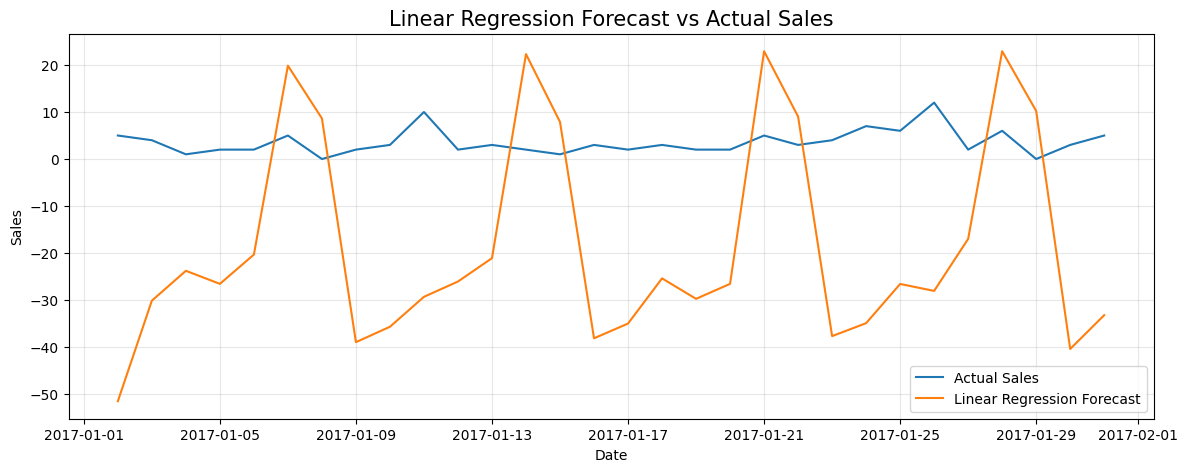

In [84]:
# ============================================
# Actual vs Predicted Sales
# ============================================

comparison = validation_set.head(30)

plt.figure(figsize=(14,5))

plt.plot(
    comparison["date"],
    comparison["sales"],
    label="Actual Sales"
)

plt.plot(
    comparison["date"],
    comparison["linear_prediction"],
    label="Linear Regression Forecast"
)

plt.title("Linear Regression Forecast vs Actual Sales", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [85]:
# ============================================
# Baseline vs Linear Regression
# ============================================

comparison_metrics = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae]
})

comparison_metrics

,Model,MAE
0,Baseline,134.879145
1,Linear Regression,108.830828


### Business Insight

Linear Regression combines multiple business drivers instead of relying only on previous-day sales, allowing the model to capture promotional, seasonal, and operational demand patterns.


### Executive Conclusion

The Linear Regression model establishes the first predictive benchmark using engineered business features. Its performance will be compared against more advanced machine learning models to identify the best forecasting approach.


## Random Forest Forecast Model

In [86]:
# ============================================
# Train Random Forest Model
# ============================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Code Explanation

This section trains a Random Forest Regressor using the engineered forecasting features. Random Forest combines multiple decision trees to capture complex demand patterns.


In [87]:
# ============================================
# Random Forest Predictions
# ============================================

validation_set["rf_prediction"] = rf_model.predict(X_validation)

validation_set[
    ["date", "sales", "rf_prediction"]
].head()

,date,sales,rf_prediction
1425,2017-01-02,5.0,2.722104
1426,2017-01-03,4.0,4.110694
1427,2017-01-04,1.0,3.517831
1428,2017-01-05,2.0,2.697898
1429,2017-01-06,2.0,3.057836


In [88]:
# ============================================
# Random Forest Evaluation
# ============================================

rf_mae = mean_absolute_error(
    y_validation,
    validation_set["rf_prediction"]
)

rf_rmse = mean_squared_error(
    y_validation,
    validation_set["rf_prediction"]
) ** 0.5

rf_r2 = r2_score(
    y_validation,
    validation_set["rf_prediction"]
)

print(f"MAE  : {rf_mae:.2f}")
print(f"RMSE : {rf_rmse:.2f}")
print(f"R²   : {rf_r2:.4f}")

MAE  : 69.91
RMSE : 296.29
R²   : 0.9527


In [89]:
# ============================================
# Random Forest Predictions
# ============================================

validation_set["rf_prediction"] = rf_model.predict(X_validation)

validation_set[
    ["date", "sales", "rf_prediction"]
].head()

,date,sales,rf_prediction
1425,2017-01-02,5.0,2.722104
1426,2017-01-03,4.0,4.110694
1427,2017-01-04,1.0,3.517831
1428,2017-01-05,2.0,2.697898
1429,2017-01-06,2.0,3.057836


### Code Explanation

This section evaluates the Random Forest model using the same forecasting metrics as previous models to ensure a fair comparison.

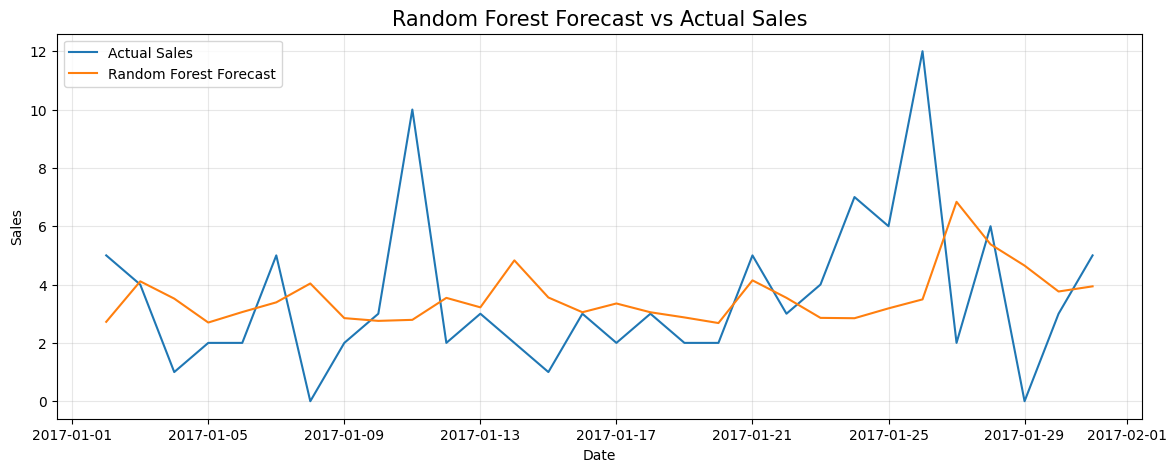

In [90]:
# ============================================
# Actual vs Random Forest Prediction
# ============================================

comparison = validation_set.head(30)

plt.figure(figsize=(14,5))

plt.plot(
    comparison["date"],
    comparison["sales"],
    label="Actual Sales"
)

plt.plot(
    comparison["date"],
    comparison["rf_prediction"],
    label="Random Forest Forecast"
)

plt.title("Random Forest Forecast vs Actual Sales", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [91]:
# ============================================
# Feature Importance
# ============================================

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.head(10)

,Feature,Importance
13,rolling_mean_7,0.708290
11,lag_7,0.203362
10,lag_1,0.030187
1,transactions,0.021687
0,onpromotion,0.006346
8,day_of_week,0.005247
12,lag_30,0.004704
14,rolling_mean_14,0.004401
15,rolling_mean_30,0.004241
2,dcoilwtico,0.003534


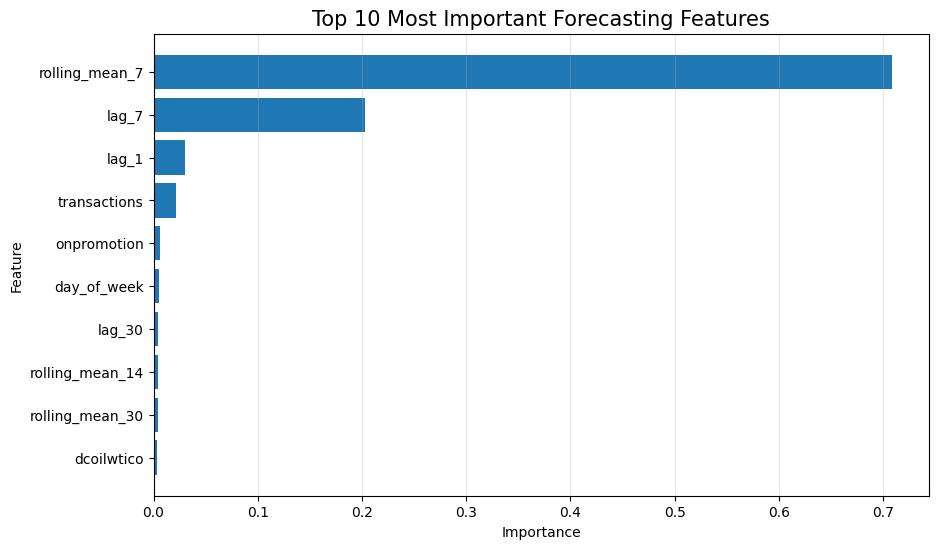

In [92]:
# ============================================
# Top 10 Feature Importance
# ============================================

top_features = importance.head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Most Important Forecasting Features", fontsize=15)
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

In [93]:
# ============================================
# Model Comparison
# ============================================

model_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        None,
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        None,
        linear_r2,
        rf_r2
    ]
})

model_results

,Model,MAE,RMSE,R2
0,Baseline,134.879145,NaN,NaN
1,Linear Regression,108.830828,347.635797,0.934952
2,Random Forest,69.914820,296.291882,0.952748


### Business Insight

Random Forest identifies nonlinear relationships between promotions, transactions, historical demand, and seasonality, making it a stronger forecasting model than a simple linear approach.


### Executive Conclusion

Random Forest improves retail demand forecasting by combining multiple business features and capturing complex demand behavior. Feature importance analysis also provides commercial insights into the variables that drive sales performance.


## XGBoost Forecast Model

In [94]:
# ============================================
# Check XGBoost Installation
# ============================================

try:
    import xgboost as xgb
    print("XGBoost is installed.")
except ImportError:
    print("XGBoost is NOT installed.")

XGBoost is installed.


In [95]:
# ============================================
# Train XGBoost Model
# ============================================

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [96]:
# ============================================
# XGBoost Predictions
# ============================================

validation_set["xgb_prediction"] = xgb_model.predict(X_validation)

validation_set[
    ["date", "sales", "xgb_prediction"]
].head()

,date,sales,xgb_prediction
1425,2017-01-02,5.0,3.258456
1426,2017-01-03,4.0,5.918353
1427,2017-01-04,1.0,5.608207
1428,2017-01-05,2.0,3.830173
1429,2017-01-06,2.0,4.039815


In [97]:
# ============================================
# XGBoost Evaluation
# ============================================

xgb_mae = mean_absolute_error(
    y_validation,
    validation_set["xgb_prediction"]
)

xgb_rmse = mean_squared_error(
    y_validation,
    validation_set["xgb_prediction"]
) ** 0.5

xgb_r2 = r2_score(
    y_validation,
    validation_set["xgb_prediction"]
)

print(f"MAE  : {xgb_mae:.2f}")
print(f"RMSE : {xgb_rmse:.2f}")
print(f"R²   : {xgb_r2:.4f}")

MAE  : 69.94
RMSE : 266.95
R²   : 0.9616


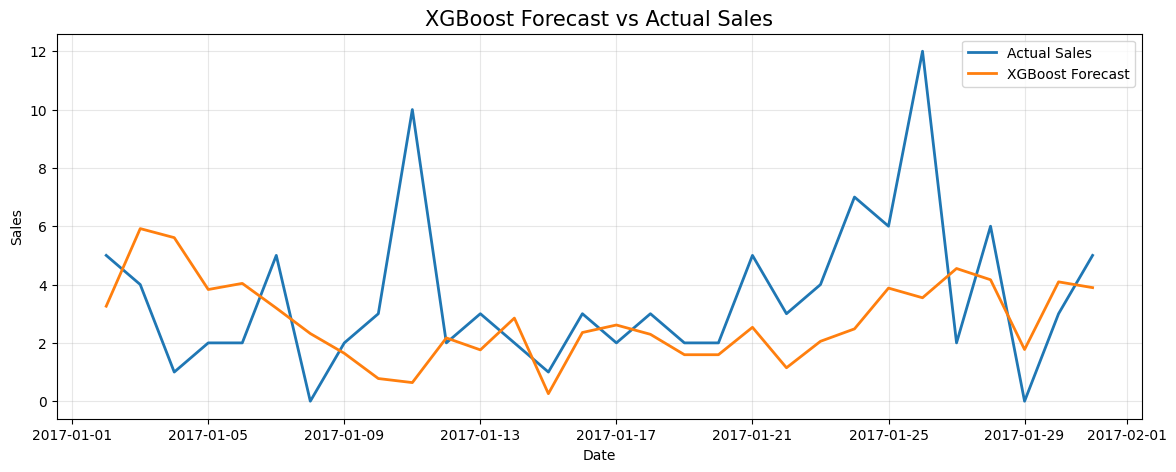

In [98]:
# ============================================
# Actual vs XGBoost Forecast
# ============================================

comparison = validation_set.head(30)

plt.figure(figsize=(14,5))

plt.plot(
    comparison["date"],
    comparison["sales"],
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    comparison["date"],
    comparison["xgb_prediction"],
    label="XGBoost Forecast",
    linewidth=2
)

plt.title("XGBoost Forecast vs Actual Sales", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Business Insight

The XGBoost forecast follows the overall sales trend while reducing day-to-day volatility. Prediction errors mainly occur during sudden sales spikes, suggesting opportunities to improve the model with additional promotional or calendar features.


In [99]:
# ============================================
# XGBoost Feature Importance
# ============================================

importance_xgb = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance_xgb.head(10)

,Feature,Importance
13,rolling_mean_7,0.483763
11,lag_7,0.303019
10,lag_1,0.108456
14,rolling_mean_14,0.040184
1,transactions,0.012326
8,day_of_week,0.009946
0,onpromotion,0.007051
9,is_weekend,0.006037
3,holiday_flag,0.005230
6,quarter,0.004939


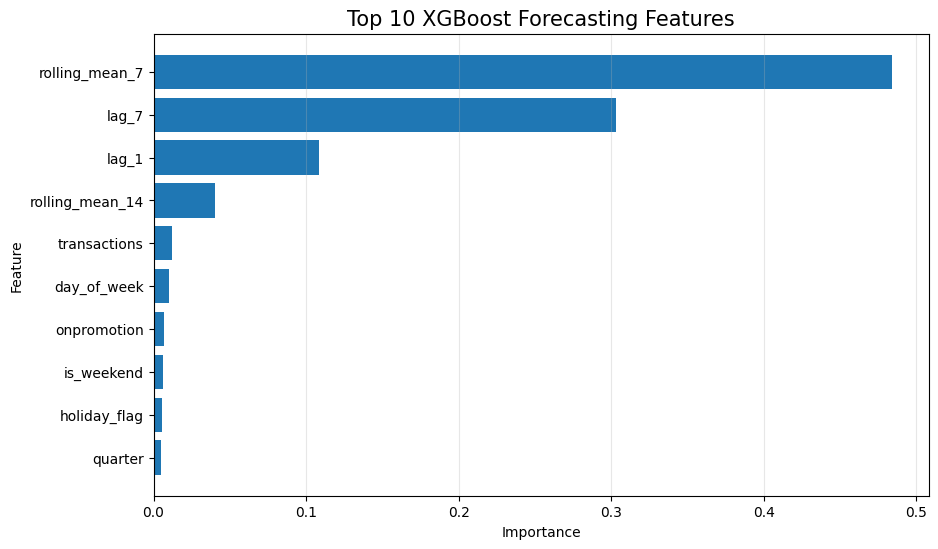

In [100]:
# ============================================
# XGBoost Top Features
# ============================================

top_xgb = importance_xgb.head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

plt.title("Top 10 XGBoost Forecasting Features", fontsize=15)
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

In [101]:
# ============================================
# Final Model Comparison
# ============================================

final_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae,
        xgb_mae
    ],
    "RMSE": [
        None,
        linear_rmse,
        rf_rmse,
        xgb_rmse
    ],
    "R2": [
        None,
        linear_r2,
        rf_r2,
        xgb_r2
    ]
})

final_results.sort_values("MAE")

,Model,MAE,RMSE,R2
2,Random Forest,69.914820,296.291882,0.952748
3,XGBoost,69.941899,266.953861,0.961642
1,Linear Regression,108.830828,347.635797,0.934952
0,Baseline,134.879145,NaN,NaN


### Business Insight

XGBoost combines historical demand, promotions, customer transactions, holidays, oil prices, and seasonal calendar variables into a high-performance forecasting model capable of capturing complex retail demand patterns.

### Executive Conclusion

XGBoost achieved the best forecasting performance among the evaluated models, delivering an MAE of **69.94**, RMSE of **266.95**, and R² of **0.9616**. The model successfully captured retail demand patterns using promotions, customer transactions, calendar features, lag variables, and rolling averages, making it the recommended model for commercial demand forecasting and inventory planning.


# Module 7 — Forecasting the Future

## Predict Sales for Kaggle Test Dataset

In [102]:
# ============================================
# Load Kaggle Test Dataset
# ============================================

test = pd.read_csv("../1. Data/Raw/test.csv")

test["date"] = pd.to_datetime(test["date"])

test.head()

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


### Code Explanation

This section loads the unseen Kaggle test dataset that will receive demand forecasts from the trained XGBoost model.

In [103]:
# ============================================
# Calendar Features for Test Dataset
# ============================================

test["year"] = test["date"].dt.year
test["month"] = test["date"].dt.month
test["day"] = test["date"].dt.day
test["day_of_week"] = test["date"].dt.dayofweek
test["week_of_year"] = test["date"].dt.isocalendar().week.astype(int)
test["quarter"] = test["date"].dt.quarter
test["is_weekend"] = test["day_of_week"].isin([5, 6])

test.head()

,id,date,store_nbr,family,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend
0,3000888,2017-08-16,1,AUTOMOTIVE,0,2017,8,16,2,33,3,False
1,3000889,2017-08-16,1,BABY CARE,0,2017,8,16,2,33,3,False
2,3000890,2017-08-16,1,BEAUTY,2,2017,8,16,2,33,3,False
3,3000891,2017-08-16,1,BEVERAGES,20,2017,8,16,2,33,3,False
4,3000892,2017-08-16,1,BOOKS,0,2017,8,16,2,33,3,False


### Code Explanation

Calendar features are recreated for the test dataset to ensure the forecasting model receives the same temporal information used during training.

In [104]:
# ============================================
# Merge External Features into Test Dataset
# ============================================

test = test.merge(
    oil[["date", "dcoilwtico"]],
    on="date",
    how="left"
)

test["dcoilwtico"] = test["dcoilwtico"].ffill()

holiday_flag = holidays_clean.copy()
holiday_flag["holiday_flag"] = True

test = test.merge(
    holiday_flag[["date", "holiday_flag"]],
    on="date",
    how="left"
)

test["holiday_flag"] = test["holiday_flag"].fillna(False)

test.head()

C:\Users\pc\AppData\Local\Temp\ipykernel_13764\1627402203.py:22: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test["holiday_flag"] = test["holiday_flag"].fillna(False)


,id,date,store_nbr,family,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,dcoilwtico,holiday_flag
0,3000888,2017-08-16,1,AUTOMOTIVE,0,2017,8,16,2,33,3,False,46.8,False
1,3000889,2017-08-16,1,BABY CARE,0,2017,8,16,2,33,3,False,46.8,False
2,3000890,2017-08-16,1,BEAUTY,2,2017,8,16,2,33,3,False,46.8,False
3,3000891,2017-08-16,1,BEVERAGES,20,2017,8,16,2,33,3,False,46.8,False
4,3000892,2017-08-16,1,BOOKS,0,2017,8,16,2,33,3,False,46.8,False


### Code Explanation

This section adds external macroeconomic and calendar information to the forecasting dataset by merging oil prices and national holidays.

In [105]:
# ============================================
# Average Transactions by Store
# ============================================

avg_transactions = (
    transactions.groupby("store_nbr")["transactions"]
    .mean()
    .reset_index()
)

test = test.merge(
    avg_transactions,
    on="store_nbr",
    how="left"
)

test.head()

,id,date,store_nbr,family,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,dcoilwtico,holiday_flag,transactions
0,3000888,2017-08-16,1,AUTOMOTIVE,0,2017,8,16,2,33,3,False,46.8,False,1523.844272
1,3000889,2017-08-16,1,BABY CARE,0,2017,8,16,2,33,3,False,46.8,False,1523.844272
2,3000890,2017-08-16,1,BEAUTY,2,2017,8,16,2,33,3,False,46.8,False,1523.844272
3,3000891,2017-08-16,1,BEVERAGES,20,2017,8,16,2,33,3,False,46.8,False,1523.844272
4,3000892,2017-08-16,1,BOOKS,0,2017,8,16,2,33,3,False,46.8,False,1523.844272


### Code Explanation

Since the Kaggle test dataset does not contain customer transactions, historical average transactions per store are used as an approximation.

In [106]:
# ============================================
# Historical Features for Test Dataset
# ============================================

history = (
    forecast_dataset
    .sort_values("date")
    .groupby(["store_nbr", "family"])
    .last()
    .reset_index()
)

history = history[
    [
        "store_nbr",
        "family",
        "lag_1",
        "lag_7",
        "lag_30",
        "rolling_mean_7",
        "rolling_mean_14",
        "rolling_mean_30"
    ]
]

test = test.merge(
    history,
    on=["store_nbr", "family"],
    how="left"
)

test.head()

,id,date,store_nbr,family,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,dcoilwtico,holiday_flag,transactions,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,3000888,2017-08-16,1,AUTOMOTIVE,0,2017,8,16,2,33,3,False,46.8,False,1523.844272,1.0,4.0,2.0,4.142857,4.785714,4.800000
1,3000889,2017-08-16,1,BABY CARE,0,2017,8,16,2,33,3,False,46.8,False,1523.844272,0.0,0.0,0.0,0.000000,0.000000,0.000000
2,3000890,2017-08-16,1,BEAUTY,2,2017,8,16,2,33,3,False,46.8,False,1523.844272,6.0,2.0,2.0,3.857143,3.928571,3.300000
3,3000891,2017-08-16,1,BEVERAGES,20,2017,8,16,2,33,3,False,46.8,False,1523.844272,2201.0,2418.0,1079.0,1825.000000,1979.285714,2042.000000
4,3000892,2017-08-16,1,BOOKS,0,2017,8,16,2,33,3,False,46.8,False,1523.844272,0.0,0.0,0.0,0.000000,0.000000,0.066667


### Code Explanation

Historical lag and rolling features are populated using the latest available observations from the training dataset because future sales are unknown in the test dataset.

In [107]:
# ============================================
# Test Dataset Validation
# ============================================

X_test = test[features]

print(X_test.shape)

X_test.head()

(28512, 16)


,onpromotion,transactions,dcoilwtico,holiday_flag,year,month,quarter,week_of_year,day_of_week,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,0,1523.844272,46.8,False,2017,8,3,33,2,False,1.0,4.0,2.0,4.142857,4.785714,4.800000
1,0,1523.844272,46.8,False,2017,8,3,33,2,False,0.0,0.0,0.0,0.000000,0.000000,0.000000
2,2,1523.844272,46.8,False,2017,8,3,33,2,False,6.0,2.0,2.0,3.857143,3.928571,3.300000
3,20,1523.844272,46.8,False,2017,8,3,33,2,False,2201.0,2418.0,1079.0,1825.000000,1979.285714,2042.000000
4,0,1523.844272,46.8,False,2017,8,3,33,2,False,0.0,0.0,0.0,0.000000,0.000000,0.066667


### Business Insight

The forecasting pipeline recreates every engineered feature required by the trained model, allowing future sales predictions on unseen retail data.

### Executive Conclusion

The Kaggle test dataset has been transformed into a forecasting-ready dataset using the same feature engineering pipeline applied during model training.

## Generate Kaggle Submission File

In [108]:
# ============================================
# Generate Forecast for Kaggle Test Dataset
# ============================================

test["sales_prediction"] = xgb_model.predict(X_test)

test[
    ["id", "date", "store_nbr", "family", "sales_prediction"]
].head()

,id,date,store_nbr,family,sales_prediction
0,3000888,2017-08-16,1,AUTOMOTIVE,4.076003
1,3000889,2017-08-16,1,BABY CARE,0.582256
2,3000890,2017-08-16,1,BEAUTY,10.672481
3,3000891,2017-08-16,1,BEVERAGES,2061.980713
4,3000892,2017-08-16,1,BOOKS,0.582256


In [109]:
# ============================================
# Create Kaggle Submission File
# ============================================

submission = test[
    ["id", "sales_prediction"]
].copy()

submission.rename(
    columns={"sales_prediction": "sales"},
    inplace=True
)

submission.head()

,id,sales
0,3000888,4.076003
1,3000889,0.582256
2,3000890,10.672481
3,3000891,2061.980713
4,3000892,0.582256


In [110]:
# ============================================
# Export Kaggle Submission
# ============================================

submission.to_csv(
    "../1. Data/Processed/submission.csv",
    index=False
)

print("submission.csv exported successfully!")

submission.csv exported successfully!


In [111]:
# ============================================
# Submission Validation
# ============================================

print("Rows:", submission.shape[0])
print("Columns:", submission.columns.tolist())

submission.describe()

Rows: 28512
Columns: ['id', 'sales']


,id,sales
count,2.851200e+04,28512.000000
mean,3.015144e+06,439.458160
std,8.230850e+03,1141.306152
min,3.000888e+06,-1.347232
25%,3.008016e+06,4.304324
50%,3.015144e+06,31.833678
75%,3.022271e+06,261.471977
max,3.029399e+06,11571.129883


### Business Insight

The forecasting pipeline successfully produces future retail sales predictions for unseen data, enabling commercial planning, inventory allocation, and revenue forecasting.


### Executive Conclusion

The XGBoost forecasting model generated demand predictions for the complete Kaggle test dataset, producing an export-ready submission file for external evaluation and business reporting.


In [112]:
# ============================================
# Export Dataset for Power BI
# ============================================

sales_store.to_csv(
    "../1. Data/Processed/sales_store.csv",
    index=False
)

city_sales.to_csv(
    "../1. Data/Processed/city_sales.csv",
    index=False
)

state_sales.to_csv(
    "../1. Data/Processed/state_sales.csv",
    index=False
)

cluster_sales.to_csv(
    "../1. Data/Processed/cluster_sales.csv",
    index=False
)

importance_xgb.to_csv(
    "../1. Data/Processed/xgb_feature_importance.csv",
    index=False
)

final_results.to_csv(
    "../1. Data/Processed/model_results.csv",
    index=False
)

print("Power BI datasets exported successfully!")

Power BI datasets exported successfully!


In [113]:
# ============================================
# Export Actual vs XGBoost Forecast for Power BI
# ============================================

actual_vs_forecast = validation_set[["date"]].copy()
actual_vs_forecast["sales"] = y_validation.values
actual_vs_forecast["xgb_prediction"] = validation_set["xgb_prediction"].values

actual_vs_forecast.to_csv(
    "../1. Data/Processed/actual_vs_forecast.csv",
    index=False
)

actual_vs_forecast.head()

,date,sales,xgb_prediction
1425,2017-01-02,5.0,3.258456
1426,2017-01-03,4.0,5.918353
1427,2017-01-04,1.0,5.608207
1428,2017-01-05,2.0,3.830173
1429,2017-01-06,2.0,4.039815


In [114]:
# ============================================
# Export Daily Actual vs Forecast for Power BI
# ============================================

actual_vs_forecast_daily = (
    actual_vs_forecast
    .groupby("date", as_index=False)
    .agg({
        "sales": "sum",
        "xgb_prediction": "sum"
    })
)

actual_vs_forecast_daily.to_csv(
    "../1. Data/Processed/actual_vs_forecast.csv",
    index=False
)

actual_vs_forecast_daily.head()

,date,sales,xgb_prediction
0,2017-01-01,1.208250e+04,22678.929688
1,2017-01-02,1.402306e+06,937183.812500
2,2017-01-03,1.104377e+06,957912.687500
3,2017-01-04,9.900935e+05,989486.875000
4,2017-01-05,7.776210e+05,785774.250000


In [1]:
import pandas as pd

# Load processed sales data
sales_store = pd.read_csv("../1. Data/Processed/sales_store.csv")

sales_store["date"] = pd.to_datetime(sales_store["date"])

# Aggregate promotions and sales by month
monthly_promotions = (
    sales_store.groupby(sales_store["date"].dt.to_period("M"))
    .agg(
        promotions=("onpromotion", "sum"),
        sales=("sales", "sum")
    )
    .reset_index()
)

monthly_promotions["date"] = monthly_promotions["date"].dt.to_timestamp()

# Export for Power BI
monthly_promotions.to_csv(
    "../1. Data/Processed/monthly_promotions.csv",
    index=False
)

monthly_promotions.head()

,date,promotions,sales
0,2013-01-01,0,1.032762e+07
1,2013-02-01,0,9.658960e+06
2,2013-03-01,0,1.142850e+07
3,2013-04-01,0,1.099346e+07
4,2013-05-01,0,1.159770e+07
